# Real-time carbon accounting and material transition for hydrogen systems

__author__ = "Marco De Sousa"
__copyright__ = "Copyright 2023, Multi-parametric Optimization & Control Lab"
__credits__ = ["Marco De Sousa", "Rahul Kakodkar", "Efstratios N. Pistikopoulos"]
__license__ = "MIT"
__version__ = "1.1.0"
__maintainer__ = "Marco De Sousa"
__email__ = "marcopdsousa@tamu.edu"
__status__ = "Production"


## Problem Statement

The following case study considers three different type of solar photovoltaics, namely Monocrystalline (PV_Mo), Polycrystalline (PV_Po), and Cadmium Telluride (PV_Cd) and  Lithium-ion batteries made of either rock-based lithium (LiI_Ro) or brine-based lithium (LiI_Br).

The goal is to meet a fixed demand of hydrogen on a daily scale while optimizing the production process by using forecasting techniques.

It is important to note that three different hydrogen pathways can be utilized each with their respective emissions.

Hypothesis: By using real-time carbon accounting, decisions and changes can be made in a more dynamic nature.

Users are advised caution in terms of assigning the emissions at the appropriate levels and avoiding double account. For example, if providing the global warming potentials (GWP) for each individual material to make up a process, the GWP for processes should only consider the values for construction. Moreover, the direct emissions are considered through the resource balance constraint.

## Nomenclature



*Sets*


$\mathcal{R}$ - set of all resources r

$\mathcal{P}$ - set of all processes p

$\mathcal{T}$ - set of temporal periods t

$\mathcal{B}$ - set of transport modes b

$\mathcal{L}$ - set of locations l

$\mathcal{M}$ - set of materials m

*Subsets*


$\mathcal{R}^{storage}$ - set of resources that can be stored

$\mathcal{R}^{sell}$ - set of resources that can be discharged

$\mathcal{R}^{demand}$ - set of resources that meet  demand

$\mathcal{R}^{cons}$ - set of resources that can be consumed

$\mathcal{R}^{trans}$ - set of resources that can be transported

$\mathcal{P}^{uncertain}$ - set of processes with uncertain capacity

$\mathcal{T}^{net}$ - set of temporal periods t for network level decision making

$\mathcal{T}^{sch}$ - set of temporal periods t for schedule level decision making

*Continuous Variables*


$P_{l,p,t}$ - production level of p $\in$  $\mathcal{P}$ in time period t $\in$ $\mathcal{T}^{sch}$  

$C_{l,r,t}$ - consumption of r $\in$ in $\mathcal{R}^{cons}$ time period t $\in$ $\mathcal{T}^{sch}$ 

$S_{l,r,t}$ - discharge of r $\in$ in $\mathcal{R}^{demand}$ time period t $\in$ $\mathcal{T}^{sch}$ 

$Inv_{l,r,t}$ - inventory level of r $\in$ $\mathcal{R}^{storage}$  in time period t $\in$ $\mathcal{T}^{sch}$

$Cap^S_{l,r,t}$ - installed inventory capacity for resource r $\in$  $\mathcal{R}^{storage}$ in time period t $\in$ $\mathcal{T}^{net}$

$Cap^P_{l,p,t}$ - installed production capacity for process p $\in$ $\mathcal{P}$ in time period t $\in$ $\mathcal{T}^{net}$

$Mat^P_{l,p,m,t}$ - material m $\in$ $\mathcal{M}$ used by process p $\in$ $\mathcal{P}$ in time period t $\in$ $\mathcal{T}^{net}$

$Em^{p/r/m}_{l,p/r/m,t}$ - emission from process/resource/material in time t $\in$ $\mathcal{T}^{net}$


*Binary Variables*

$X^P_{l,p,t}$ - network binary for production process p $\in$ $\mathcal{P}$

$X^S_{l,r,t}$ - network binary for inventory of resource r $\in$  $\mathcal{R}^{storage}$ 

*Parameters*

$Cap^{P-max}_{l,p,t}$ - maximum production capacity of process p $\in$ $\mathcal{P}$ in time t $\in$ $\mathcal{T}^{net}$

$Cap^{S-max}_{l,r,t}$ - maximum inventory capacity for process r $\in$ $\mathcal{R}^{storage}$ in time t $\in$ $\mathcal{T}^{net}$

$Capex_{l,p,t}$ - capital expenditure for process p $\in$ $\mathcal{P}$ in time t $\in$ $\mathcal{T}^{net}$

$Vopex_{l,p,t}$ - variable operational expenditure for process p $\in$ $\mathcal{P}$ in time t $\in$ $\mathcal{T}^{sch}$

$Price_{l,r,t}$ - purchase price for resource r $\in$ $\mathcal{R}^{cons}$ in time t $\in$ $\mathcal{T}^{sch}$

$C^{max}_{l,r,t}$ - maximum consumption availability for resource r $\in$ $\mathcal{R}^{cons}$ in time t $\in$ $\mathcal{T}^{sch}$

$D_{l,r,t}$ - demand for resource r $in$ $\mathcal{R}^{sell}$ in time t $\in$ $\mathcal{T}^{sch}$

$\alpha$ - annualization factor

$Mat^{cons}_{p,m}$ - material m $\in$ $\mathcal{M}$ consumed by process p $\in$ $\mathcal{P}$

$GWP^{p/r/m}_{l,p/r/m,t}$ - global warming indicators for process/resource/material in time t $\in$ $\mathcal{T}^{net}$


## MILP Formulation

Given is a mulit-scale modeling and optimization MILP framework for the simultaneous design and schedule planning of a single location energy system 

\begin{equation}
min \sum_{l \in \mathcal{L}} \Big(\sum_{t \in \mathcal{T}^{net}} \sum_{p \in \mathcal{P}} (\alpha \times Capex_{l,p,t} + Fopex_{l,p,t}) \times Cap^P_{l,p,t} +  \sum_{t \in \mathcal{T}^{sch}} \sum_{r \in \mathcal{R}}  Vopex_{l,r,t} \times P_{l,r,t} 
\end{equation}

\begin{equation*}
+ \sum_{t \in \mathcal{T}^{sch}} \sum_{r \in \mathcal{R}^{cons}} C_{l,r,t} \times Price_{l,r,t} \Big)
\end{equation*}

\begin{equation}
Cap^S_{l,r,t} \leq Cap^{S-max}_{l,r,t} \times X^S_{l,r,t} \hspace{1cm} \forall r \in \mathcal{R}^{storage}, t \in \mathcal{T}^{net}
\end{equation}

\begin{equation}
Cap^P_{l,p,t} \leq Cap^{P-max}_{l,p,t} \times X^P_{l,p,t}  \hspace{1cm} \forall p \in \mathcal{P}, t \in \mathcal{T}^{net}, l \in \mathcal{L}
\end{equation} 

\begin{equation}
P_{l,p,t} \leq Cap^{P}_{l,p,t}  \hspace{1cm} \forall p \in \mathcal{P}, t \in \mathcal{T}^{sch}
\end{equation} 

\begin{equation}
Inv_{l,r,t} \leq Cap^{S}_{l,r,t}  \hspace{1cm} \forall r \in \mathcal{R}^{storage}, t \in \mathcal{T}^{sch}
\end{equation} 


\begin{equation}
- S_{l,r,t} \leq - D_{l,r,t}  \hspace{1cm} \forall r \in \mathcal{R}, t \in \mathcal{T}^{sch}
\end{equation}

\begin{equation}
C_{l,r,t} \leq C^{max}_{l,r,t} \hspace{1cm} \forall r \in \mathcal{R}, t \in \mathcal{T}^{sch}
\end{equation}

\begin{equation}
\sum_{p \in \mathcal{P}} P_{l,p,t} \times \eta(p,r) + C_{l,r,t} +  Inv_{l,r,t-1}=  Inv_{l,r,t} + S_{l,r,t}  
\end{equation}

\begin{equation*}
\forall r \in \mathcal{R}^{cons}, t \in \mathcal{T}^{sch}, l \in \mathcal{L}
\end{equation*}

\begin{equation}
Mat_{l,p,m,t} = Mat^{cons}_{p,m} \times Cap^P_{l,p,t} \hspace{1cm} \forall m \in \mathcal{M}, p \in \mathcal{P}, t \in \mathcal{T}^{net}
\end{equation}

\begin{equation}
Em^{r}_{l,r,t} = GWP^{r}_{l,r,t} \times C_{l,r,t} \hspace{1cm} \forall r \in \mathcal{R}, t \in \mathcal{T}^{sch}
\end{equation}

\begin{equation}
Em^{m}_{l,m,t} = GWP^{m}_{l,m,t} \times \sum_{p \in \mathcal{P}} Mat_{l,p,m,t} \hspace{1cm} \forall p \in \mathcal{P}, t \in \mathcal{T}^{net}
\end{equation}

\begin{equation}
Em^{p}_{l,p,t} = GWP^{p}_{l,p,t} \times Cap_{l,p,t} \hspace{1cm} \forall p \in \mathcal{P}, t \in \mathcal{T}^{net}
\end{equation}

\begin{equation}
S_{l,r,t}, C_{l,r,t}, Inv_{l,r,t}, P_{l,p,t}, Cap^P_{l,p,t}, Cap^S_{l,r,t}, Mat_{l,p,m,t}, Em^{p/r/m}_{l,p/r/m,t} \in R_{\geq 0}
\end{equation}



## Import Modules

In [1]:
import sys
sys.path.append('../src')
from pyomo.environ import value as pyoval

In [2]:
import pandas as pd
import numpy
from energiapy.components.temporal_scale import TemporalScale
from energiapy.components.resource import Resource, VaryingResource, Scope
from energiapy.components.process import Process, VaryingProcess
from energiapy.components.material import Material
from energiapy.components.location import Location
from energiapy.components.network import Network
from energiapy.components.scenario import Scenario
from energiapy.components.transport import Transport
from energiapy.model.formulate import formulate, Constraints, Objective
from energiapy.utils.nsrdb_utils import fetch_nsrdb_data
from energiapy.plot import plot_results, plot_scenario
from energiapy.plot.plot_results import CostY, CostX
from energiapy.model.solve import solve
from itertools import product
from energiapy.components.result import Result
from itertools import product
from matplotlib import rc
import matplotlib.pyplot as plt
from energiapy.model.solve import solve
from energiapy.plot.plot_results import CostY, CostX
from energiapy.components.location import Location
from energiapy.plot import plot_results, plot_scenario
from energiapy.utils.nsrdb_utils import fetch_nsrdb_data
from energiapy.model.formulate import formulate, Constraints, Objective
from energiapy.model.bounds import CapacityBounds
from energiapy.utils.data_utils import get_data, make_henry_price_df, remove_outliers, load_results
from energiapy.conversion.photovoltaic import solar_power_output
from energiapy.conversion.windmill import wind_power_output
from energiapy.model.constraints.integer_cuts import constraint_block_integer_cut, constraint_block_integer_cut_min

## Data Import

In [3]:
horizon = 1

The following data is needed for the model

- Daily demands of hydrogen.
- The capacity factor of renewable energy sources and traditional grid power.


**Declare temporal scale**

The variabilities of energy systems are best captured over a discretized spatio-temporal scale. In energiapy, the first declaration is the temporal scale. 

For e.g.: Here we declare three temporal scales at different levels from right to left. The interpretation of these scales is merely symentic. Scales can be declared as the problem demands.
- 0, annual, with 1 discretization
- 1, daily with 365 discretization
- 2, hourly with 24 discretization

In essence, we are creating a temporal scale of 8760 points.



In [4]:
scales = TemporalScale(discretization_list=[1,365,24])

## Declare resources

Resources can be consumed, produced, stored, discharged (or sold).

Power demand follows a varying deterministic demand

In [5]:
bigM = 10**8
smallM = 0.001

Hourly electricity prices

In [6]:
elec_price_df = pd.read_csv('C:/Users/marcopdsousa/Documents/energiapy/ESCAPE/Belgium Data/2024 Hourly Prices Belgium.csv')
#elec_price_df = elec_price_df[elec_price_df['SettlementPoint'] == 'HB_HOUSTON']  'Price (EUR/MWhe)'
elec_price_df = elec_price_df[['(USD/MWhe)']].reset_index(drop = True)
elec_price_df = elec_price_df[:8760]
elec_price_df['(USD/MWhe)'] = elec_price_df['(USD/MWhe)'].clip(lower=0)
elec_price_df

,(USD/MWhe)
0,0.0114
1,0.0000
2,0.0000
3,0.0000
4,0.0000
...,...
8755,123.3252
8756,114.2964
8757,113.0766
8758,94.3122


Hourly Natural Gas Prices

In [7]:
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# 1. Load natural gas price data
# ============================================================
file_path = Path(r"C:\Users\marcopdsousa\Documents\energiapy\AICHE\Historical natural gas prices\Natural gas historical data.csv")

NG_price_df = pd.read_csv(file_path)

price_col = "Henry Hub Natural Gas Spot Price (Dollars per Million Btu)"

NG_price_df = NG_price_df[[price_col]].copy()
NG_price_df[price_col] = pd.to_numeric(NG_price_df[price_col], errors="coerce")

# ============================================================
# 2. Convert daily prices to hourly prices
# ============================================================
hours_per_day = 24
n_hours = 8784  # Use 8760 for non-leap years; 2024 has 8784 hours

NG_price_hourly = NG_price_df.reindex(NG_price_df.index.repeat(hours_per_day))
NG_price_hourly = NG_price_hourly.reset_index(drop=True)
NG_price_hourly = NG_price_hourly.iloc[:n_hours].copy()

# ============================================================
# 3. Remove outliers beyond 3 standard deviations
# ============================================================
mean = NG_price_hourly[price_col].mean()
std = NG_price_hourly[price_col].std()

outliers = np.abs(NG_price_hourly[price_col] - mean) > 3 * std
NG_price_hourly.loc[outliers, price_col] = np.nan

fill_value = NG_price_hourly[price_col].mean()
NG_price_hourly[price_col] = NG_price_hourly[price_col].fillna(fill_value)

# ============================================================
# 4. Convert units
# ============================================================
# Henry Hub is reported in $/MMBtu.
# Approximate conversion using natural gas HHV:
# 1 MMBtu = 1055.056 MJ
# Natural gas HHV ≈ 55.5 MJ/kg
MJ_per_MMBtu = 1055.056
MJ_per_kg_NG = 55.5

NG_price_hourly["NG price ($/MMBtu)"] = NG_price_hourly[price_col]
NG_price_hourly["NG price ($/kg NG)"] = (
    NG_price_hourly["NG price ($/MMBtu)"] * MJ_per_kg_NG / MJ_per_MMBtu
)

NG_price_hourly["hour"] = range(len(NG_price_hourly))

# Optional timestamp column for 2024
NG_price_hourly["datetime_utc"] = pd.date_range(
    start="2024-01-01 00:00",
    periods=len(NG_price_hourly),
    freq="h"
)

NG_price_hourly = NG_price_hourly[
    ["datetime_utc", "hour", "NG price ($/MMBtu)", "NG price ($/kg NG)"]
]

# ============================================================
# 5. Save to Excel
# ============================================================
output_path = Path(r"C:\Users\marcopdsousa\Documents\energiapy\AICHE\Historical natural gas prices\Cleaned_Natural_Gas_Prices_Hourly.xlsx")

NG_price_hourly.to_excel(output_path, index=False)

print(f"Saved cleaned hourly natural gas prices to: {output_path}")

Saved cleaned hourly natural gas prices to: C:\Users\marcopdsousa\Documents\energiapy\AICHE\Historical natural gas prices\Cleaned_Natural_Gas_Prices_Hourly.xlsx


In [8]:
# #The natural gas price is calculated as the average between the high and low cost, also the unit used is $/kg of natural gas
# NG_price_df = pd.read_csv('C:/Users/marcopdsousa/Documents/energiapy/Real-Time/Dataset/23 June Belgium.csv')
# # NG_price_df = pd.DataFrame(NG_price_df['USD/kg'])[::-1].reset_index()
# NG_price_df = NG_price_df[['NG_Price']]
# NG_price_df = NG_price_df[:24]
# NG_price_df

#The natural gas price is calculated as the average between the high and low cost, also the unit used is $/kg of natural gas
NG_price_df = pd.read_csv('C:/Users/marcopdsousa/Documents/energiapy/AICHE/Historical natural gas prices/Natural gas historical data.csv')
NG_price_df = NG_price_df[['Henry Hub Natural Gas Spot Price (Dollars per Million Btu)']]
# NG_price_df = NG_price_df[:24]
NG_price_df
NG_price_hourly = NG_price_df.reindex(NG_price_df.index.repeat(30))
NG_price_hourly = NG_price_hourly[:8760]
NG_price_hourly
NG_price_hourly = pd.DataFrame(NG_price_hourly)

mean = NG_price_hourly.mean()
std = NG_price_hourly.std()


outliers = numpy.abs(NG_price_hourly - mean) > 3 * std
# Prune outliers beyond 3 standard deviations
NG_price_hourly = NG_price_hourly.mask(outliers)
fill_value = NG_price_hourly.mean()
NG_price_hourly = NG_price_hourly.fillna(fill_value)
NG_price_hourly


,Henry Hub Natural Gas Spot Price (Dollars per Million Btu)
0,2.39
0,2.39
0,2.39
0,2.39
0,2.39
...,...
291,4.63
291,4.63
291,4.63
291,4.63


In [9]:
#The natural gas price is calculated as the average between the high and low cost, also the unit used is $/kg of natural gas
Demand_df = pd.read_csv('C:/Users/marcopdsousa/Documents/energiapy/ESCAPE/Belgium Data/Belgium_H2_Demand_2024.csv')
# NG_price_df = pd.DataFrame(NG_price_df['USD/kg'])[::-1].reset_index()
Demand_df = Demand_df[['Hydrogen_Demand_kg_per_day']]
Demand_df = Demand_df[:365].reset_index(drop = True)
Demand_df

,Hydrogen_Demand_kg_per_day
0,374133.83
1,361866.59
2,373656.88
3,355088.91
4,367889.56
...,...
360,370519.18
361,377831.44
362,357199.97
363,350742.39


In [10]:
# Demand_df.plot()

In [11]:
# #The natural gas price is calculated as the average between the high and low cost, also the unit used is $/kg of natural gas
# Demand_df = pd.read_csv('RT 06 JUNE.csv')
# # NG_price_df = pd.DataFrame(NG_price_df['USD/kg'])[::-1].reset_index()
# Demand_df = Demand_df[['demand']]
# Demand_df = Demand_df[:24]
# Demand_df

In [12]:
# #The natural gas price is calculated as the average between the high and low cost, also the unit used is $/kg of natural gas
# GWP_df = pd.read_csv('C:/Users/marcopdsousa/Documents/energiapy/ESCAPE/Belgium Data/2024 Carbon Intensity Belgium.csv')
# # NG_price_df = pd.DataFrame(NG_price_df['USD/kg'])[::-1].reset_index()
# GWP_df = GWP_df[['Carbon intensity Full']]
# GWP_df = GWP_df[:8760].reset_index(drop = True)
# GWP_df

In [13]:
# GWP_df.max()

In [14]:
#Gives relevancy to price values again
elec_price = elec_price_df.max()[0]
NG_price = NG_price_df.max()[0]
# GWP_value = GWP_df.max()[0]
#Demand_value = Demand_df.max()[0]

C:\Users\marcopdsousa\AppData\Local\Temp\ipykernel_20444\2013703360.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  elec_price = elec_price_df.max()[0]
C:\Users\marcopdsousa\AppData\Local\Temp\ipykernel_20444\2013703360.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  NG_price = NG_price_df.max()[0]


Hourly Wind availability

In [15]:
Wind_df = pd.read_csv('C:/Users/marcopdsousa/Documents/energiapy/ESCAPE/Belgium Data/2024 Wind Flanders.csv')
Wind_df = Wind_df[['Wind_avg_MW']]
Wind_df = Wind_df[:8760]
Wind_df

,Wind_avg_MW
0,0.64625
1,0.64125
2,0.63250
3,0.65000
4,0.64750
...,...
8755,0.28125
8756,0.29125
8757,0.27125
8758,0.23000


Hourly Solar availability

In [16]:
# import pandas as pd

# # Step 1: Load the CSV (adjust delimiter if needed)
# df = pd.read_csv("C:/Users/marcopdsousa/Documents/energiapy/ESCAPE/Belgium Data/2024 Wind Belgium.csv", delimiter=";")

# # Step 2: Check the column names to locate region + datetime
# print("Columns:", df.columns)

In [17]:
# import numpy as np
# import pandas as pd

# # Set seed for reproducibility
# np.random.seed(42)

# # Create a date range for one year
# date_range = pd.date_range(start="2024-01-01", end="2024-12-31", freq="D")

# # Base daily average (kg/day)
# base_demand = 356_000

# # Seasonal effect: Higher winter use for heating (residential)
# seasonal_effect = 1 + 0.1 * np.cos(2 * np.pi * (date_range.dayofyear - 15) / 365)

# # Random daily variability by sector (in percent)
# industry_variation = np.random.normal(0, 0.01, len(date_range))  # ±1%
# mobility_variation = np.random.normal(0, 0.15, len(date_range))  # ±15%
# residential_variation = np.random.normal(0, 0.05, len(date_range))  # ±5%

# # Sector shares
# industry_share = 0.7
# mobility_share = 0.2
# residential_share = 0.1

# # Compute total daily demand
# daily_demand = (
#     base_demand
#     * (
#         industry_share * (1 + industry_variation)
#         + mobility_share * (1 + mobility_variation)
#         + residential_share * (1 + residential_variation) * seasonal_effect
#     )
# )

# # Ensure no negative demand
# daily_demand = np.maximum(daily_demand, 0)

# # Create DataFrame
# hydrogen_demand_df = pd.DataFrame({
#     "Date": date_range,
#     "Hydrogen_Demand_kg_per_day": daily_demand.round(2)
# })

# # Save to CSV (optional)
# # hydrogen_demand_df.to_csv("Belgium_H2_Demand_2024.csv", index=False)

# # Display head
# hydrogen_demand_df.head()


In [18]:
# import pandas as pd

# # Step 1: Load the CSV (adjust delimiter if needed)
# df = pd.read_csv("C:/Users/marcopdsousa/Documents/energiapy/ESCAPE/Belgium Data/2024 Wind Belgium.csv", delimiter=";")

# # Step 2: Check the column names to locate region + datetime
# print("Columns:", df.columns)

# # Example: your file may have columns like:
# # ['Datetime', 'Region', 'Technology', 'Production [MW]']

# # Step 3: Convert datetime (with UTC to suppress warning)
# datetime_col = 'Datetime'  # adjust if your file shows a different name
# df[datetime_col] = pd.to_datetime(df[datetime_col], errors='coerce', utc=True)

# # Step 4: Drop rows with missing datetime
# df = df.dropna(subset=[datetime_col])

# # Step 5: Filter only Flanders rows
# # Adjust column name if it's not exactly 'Region'
# df_flanders = df[df['Region'].str.lower() == 'flanders']

# # Step 6: Floor datetime to the hour
# df_flanders['hour'] = df_flanders[datetime_col].dt.floor('H')

# # Step 7: Aggregate to hourly average
# # Adjust the production column name if it's different (like 'Production [MW]')
# df_hourly = df_flanders.groupby('hour')["Load factor"].mean().reset_index()
# df_hourly.columns = ['datetime', 'Wind_avg_MW']

# # Step 8: Save to CSV
# df_hourly.to_csv("wind_hourly_avg_MW_flanders.csv", index=False)

In [19]:
Solar_df = pd.read_csv('C:/Users/marcopdsousa/Documents/energiapy/ESCAPE/Belgium Data/2024 Solar Flanders.csv')
Solar_df = Solar_df[['solar_avg_MW']]
Solar_df = Solar_df[:8760]
Solar_df



,solar_avg_MW
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0
...,...
8755,0.0
8756,0.0
8757,0.0
8758,0.0


In [20]:
Solar = Resource(name='Solar', cons_max=bigM, basis='MW', label='Solar Power', price= 68.35, gwp=0, scope=Scope.TWO)
#52.69 USD/MWH
#62.83
#https://www.pv-tech.org/levelten-european-solar-ppa-prices-fall-27-stable-north-america/

Wind = Resource(name='Wind', cons_max=bigM, basis='MW', label='Wind Power', price= 104.70, gwp=0, scope=Scope.TWO)
#60.11 USD/MWH
#72.00
#chrome-extension://efaidnbmnnnibpcajpcglclefindmkaj/https://inspiratia.com/files/file/european-ppa-outlook.pdf
#https://taiyangnews.info/business/european-wind-solar-ppa-prices-stabilize-in-q22024

Power = Resource(name='Power', basis='MW',
                 label='Power generated')

# GridPower = Resource(name='GridPower', basis='MW',
#                      cons_max=bigM, label='Power bought', gwp=420.62, price = ecombined, varying = [VaryingResource.DETERMINISTIC_PRICE], scope = Scope.TWO)

GridPower = Resource(name='GridPower', basis='MW',
                     cons_max=bigM, label='Power bought', gwp= 150, price =elec_price ,varying = [VaryingResource.DETERMINISTIC_PRICE], scope = Scope.TWO)

#The following are components of natural gas

CO2 = Resource(name='CO2', basis='kg/hr',
               label='Carbon dioxide', block='Resource')

CO2_Stack = Resource(name='CO2 to Stack', basis='kg/hr', sell=True,
               label='Carbon dioxide to Stack', block='Resource', gwp = 1, scope = Scope.ONE)

CO2_Air = Resource(name='CO2 from air', basis='kg/hr',
               label='Carbon dioxide from air', block='Resource', cons_max=bigM)

CO2_Vent = Resource(name='CO2 Vented from the process', basis='kg/hr',
               label='Carbon dioxide vented from the process', block='Resource', gwp = 1, sell=True, scope = Scope.ONE)

CO2cpt = Resource(name='CO2 Captured', basis='kg/hr', sell=True, label='Captured carbon dioxide', block='Resource')

#CO2_Blowdown= Resource(name='CO2 Blowdown', basis='kg/hr', sell=True, block='Resource', gwp = 1) # 2 ATR processes, imp, Stream X+20, 16+20 Declares CO2 going into the Boiler via Air stream 5 in ATR process

CH4 = Resource(name='CH4', basis='kg/hr',
               label='Methane', block='Resource')

CH4_Desorped = Resource(name='CH4_Desorped', basis='kg/hr', sell=True,
               label='Methane', block='Resource') # True for ATR Occurs during ATR process

#Important: Natural gas consists over different components

NG = Resource(name='Natural Gas', basis='kg/hr',
                     cons_max=bigM, label='Natural Gas', gwp = 0.960979, price = NG_price/20, varying = [VaryingResource.DETERMINISTIC_PRICE]) #, varying = [VaryingResource.DETERMINISTIC_PRICE])

#NG_price_hourly
# Hydrogen is what I want to sell/satisfy a specific demand for

H2 = Resource(name='Hydrogen', basis='kg/hr', label='Hydrogen', block='Resource')

H2Pure = Resource(name='Pure Hydrogen', demand = True, basis='kg/hr', label='Pure Hydrogen', block='Resource', varying=[VaryingResource.DETERMINISTIC_DEMAND])
#, varying=[VaryingResource.DETERMINISTIC_DEMAND]
# Water is required for the electrolysis process

H2O = Resource(name='H2O',
               basis='kg/hr', cons_max=bigM, label='Water', block='Resource')

#Industrial water price is 0.002 USD/kg of water
H2OFresh = Resource(name="H2O Fresh", cons_max=bigM, price = 0.002, basis='kg/hr', label='Fresh Water', block='Resource')

H2O_Air = Resource(name='H2O from air', cons_max=bigM,
               basis='kg/hr', label='Water from air', block='Resource')

H2O_Vent = Resource(name='H2O vented from the process',
               basis='kg/hr', sell=True, label='Water vented from the process', block='Resource')


H2O_Stack = Resource(name='H2O to Stack',
               basis='kg/hr', sell= True, label='Water to Stack', block='Resource')

'''Do we need h20 vent asu and just h20 vent?'''
H2O_Vent_ASU = Resource(name='H2O Vent from ASU',
               basis='kg/hr', sell= True, label='Water vented from ASU', block='Resource') # True for ATR - Stream 17

H2O_Blowdown = Resource(name='H2O in Blowdown',
               basis='kg/hr', sell= True, label='H2O present in air - Stream 5', block='Resource') # True for ATR - Stream 20

#Industrial water price is 0.002 USD/kg of water

# Air components

N2 = Resource(name='N2', basis='kg/hr',
               label='Nitrogen', block='Resource')

N2_SMR = Resource(name='N2 from SMR', basis='kg/hr',
               label='Nitrogen from SMR', block='Resource')

N2_WGS = Resource(name='N2 from WGS', basis='kg/hr',
               label='Nitrogen from WGS', block='Resource')

N2_FG = Resource(name='N2 from FG', basis='kg/hr',
               label='Nitrogen from FG', block='Resource')

N2_Air = Resource(name='N2 from Air', basis='kg/hr', cons_max= bigM,
               label='Nitrogen from Air', block='Resource')

N2_Vent = Resource(name='N2 vented from the process', basis='kg/hr', sell= True,
               label='Nitrogen vented from the process', block='Resource')

N2Prod = Resource(name='N2 in product stream', basis='kg/hr', sell = True,
               label='Nitrogen in product stream', block='Resource')

N2_Stack = Resource(name='N2 to Stack', basis='kg/hr', sell= True,
               label='Nitrogen to stack', block='Resource')

N2_Desorped = Resource(name='N2 Desorped', basis='kg/hr', sell=True,
               label='Nitrogen in CO2 desorption stream', block='Resource') # True for ATR
N2_Vented_Stack = Resource(name='N2 in Stack', basis='kg/hr', sell = True, 
               label='Nitrogen in Stack', block='Resource') # True for ATR
N2_Blowdown = Resource(name='N2 in Blowdown', basis='kg/hr', sell = True,
               label='Nitrogen in Blowdown stream', block='Resource') # True for ATR

O2 = Resource(name='O2', basis='kg/hr',
               label='Oxygen', block='Resource')

O2_Air = Resource(name='O2 from air', basis='kg/hr',
               label='Oxygen from air', block='Resource', cons_max = bigM)

O2_Vent = Resource(name='O2 vented from the process', basis='kg/hr', sell=True,
               label='Oxygen vented from the process', block='Resource')

O2_Stack = Resource(name='O2 to Stack', basis='kg/hr', sell= True,
               label='Oxygen to Stack', block='Resource')

O2_Desorped = Resource(name='O2 Desorped', basis='kg/hr', sell = True,
               label='Oxygen in CO2 desorption stream', block='Resource') # True for ATR

O2_ASU = Resource(name='O2 vented out of ASU', basis='kg/hr', sell = True,
               label='O2 vented out of ASU', block='Resource') # True for ATR

O2_Blowdown = Resource(name='O2 in Blowdown', basis='kg/hr', sell = True,
               label='O2 in Blowdown stream', block='Resource') # True for ATR

DP1 = Resource(name='DP1', basis='kg/hr', cons_max= 750, price=10, 
               label='DP1', block='Resource') #5% deviation
DP2 = Resource(name='DP2', basis='kg/hr', cons_max= 2250, price=25, 
               label='DP2', block='Resource') #15% deviation
DP3 = Resource(name='DP3', basis='kg/hr', cons_max= 4000, price= 50, 
               label='DP3', block='Resource') #27% deviation
DP4 = Resource(name='DP4', basis='kg/hr', cons_max= 5250, price= 115, 
               label='DP4', block='Resource')

In [21]:
15000*0.15

2250.0

## Declare Materials

Materials are utilized for the establishment of processes. Materials inturn require resources to be set up. 

In [22]:
'''Do I understand it correctly that I will have no material modes'''

'Do I understand it correctly that I will have no material modes'

## Declare Processes

In [23]:
'''Purchasing electricity from a traditional power production system'''

Grid = Process(name='Grid', conversion={GridPower: -1, Power: 1}, prod_min=bigM, prod_max=bigM, label='Grid', basis='MW')

PV = Process(name='PV', conversion={Solar: -1, Power: 0.22},
             prod_max=600, prod_min=600,  varying= [VaryingProcess.DETERMINISTIC_CAPACITY], label='Solar PV', basis='MW')
#PV - PPA was constructed as a 10 MWh system
# capex=0.0001, fopex=0.0001, vopex=0.0001, gwp = 0.0001

WF = Process(name='WF', conversion={Wind: -1, Power: 0.4},
             prod_max=650, prod_min=650, label='Wind mill array', varying=[VaryingProcess.DETERMINISTIC_CAPACITY], basis='MW')
#WF  - PPA was constructed as a 30 MWh system
SMR = Process(name='SMR', conversion={Power: -0.00065, NG: -3.535189, H2OFresh: -16.78877421, N2_Air: -19.2134, O2_Air: -5.88716, H2O_Air: -0.1582, CO2_Air: -0.01171, 
                                            H2Pure: 1, CO2_Stack: 9.3713,  H2O_Stack: 3.94959, N2_Stack: 19.29814, O2_Stack: 0.535434}, capex=0.2,
               vopex=0.38, fopex=0.06, prod_min=smallM, prod_max=bigM, label='SMR', basis='kg/hr')
#voped = 0.78
SMRCCS = Process(name='SMRCCS', conversion={Power: -0.00139, N2_Air: -22.2315, O2_Air: -6.811924, H2O_Air: -0.183055, CO2_Air: -0.013551, CO2_Stack: -9.3713,
                                             H2O_Vent: 3.826767, CO2cpt: 8.903, CO2_Vent: 0.46856, H2O_Stack: 0.558114, N2_Stack: 22.32218, O2_Stack: 0.6203032, }, capex=0.45,
                vopex=1.01, fopex=0.1, prod_min=smallM, prod_max=bigM, label='SMRCCS', basis='kg/hr')

PEM = Process(name='PEM', conversion={Power: -0.052, H2OFresh: -9.5,
                                            H2Pure: 1}, capex=1.5, vopex=3.43, fopex=0.7, prod_min=smallM, prod_max=bigM, label='PEM', basis='kg/hr')
#https://doi.org/10.1016/j.ijhydene.2023.04.083 - Direct carbon footprint of hydrogen generation via PEM and alkaline electrolysers using various electrical energy sources and considering cell characteristics
#1.) 1.2 capex and 3.03 vopex
#2.) 0.5 capex and 1.03 vopex
#3.) 0.109 capex and  0.22454 vopex
#4.) 0.063 capex and 0.22454 vopex
#Fact check = 6.5647:PEM, 35.06640796:AWE, 0.9375:SMR, 0.9375:ATR_CCS_R, 0.9375:ATR_CCS_R_OC - Conversion issue

ATR_CCS_R = Process(name='ATR_CCS_R', conversion= {Power: -0.0025838509316770185, NG: -3.2080287, H2OFresh: -4.8123228, H2O_Air : -0.1041653, H2O_Vent_ASU : 0.0019387, H2O_Blowdown : 1.7351222, H2O_Vent : 0.5220523,
                                                   N2_Air: -12.653394, N2_Vent: 9.970844643, N2Prod: 0.002780318, N2_Vented_Stack: 2.182324573, N2_Desorped: 0.023329689, O2_Air: -3.87607534,
                                                   O2_ASU: 0.061984387, O2_Vent: 0.0647028,  CO2_Vent: 0.44956544299999995, CO2cpt: 7.733322317, H2Pure: 1}, capex=0.35,
               vopex=0.74, fopex=0.08, prod_min=smallM, prod_max=bigM, label='ATR_CCS_R', basis='kg/hr')

#CO2_Air:-0.007711159,

# ATR_CCS_OC = Process(name='ATR_CCS_OC', conversion={Power: -0.0059130434, NG: -3.584338787, CO2_Air: -0.010770164, CO2_Vent: 0.11601384, CO2cpt: 9.192057517, N2_Air: -17.67297545, N2_Vent: 16.7175342, N2_Blowdown: 0.000797082, N2_Desorped: 0.131330546, N2Prod: 0.002780318,
#                                                     H2O_Air: -0.145487576, H2OFresh: -5.377267146, H2O_Vent_ASU: 0.003250534, H2O_Blowdown: 3.598489736, O2_Air: -6.758549377, O2_Vent: 0.10392561, H2Pure: 1}, capex=0.45,
#                vopex=0.77, fopex=0.1, prod_min=smallM, prod_max=bigM, label='ATR_CCS_OC', basis='kg/hr')

ATR_CCS_R_OC = Process(name='ATR_CCS_R_OC', conversion={Power: -0.002881987577, NG: -3.208028688,  CO2_Vent: 0.663744554, CO2cpt: 8.152141983, 
                                                        N2_Air: -12.56295099, N2_Vent: 11.88406435, N2_Blowdown: 0.008434949, N2_Desorped: 0.102417105, N2Prod: 0.002780318, 
                                                        H2OFresh: -4.812322829, H2O_Air: -0.103420802, H2O_Vent_ASU: 0.002310721, H2O_Blowdown: 0.004504513, O2_Air: -4.804359335, 
                                                        O2_Vent: 0.073878039, H2Pure: 1}, capex=0.35,
               vopex=0.75, fopex=0.1, prod_min=smallM, prod_max=bigM, label='ATR_CCS_R_OC', basis='kg/hr')
#CO2_Air: -0.007656042,

AWE = Process(name='AWE', conversion={Power: -0.06, H2OFresh: -9.4635,
                                            H2Pure: 1}, capex=0.810127,vopex=3.850633, fopex=0.202532, prod_min=smallM, prod_max=bigM, label='AWE', basis='kg/hr')

D1 = Process(name="D1", conversion={DP1:-1, H2Pure:1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D1', basis='kg/hr')
D2 = Process(name="D2", conversion={DP2:-1, H2Pure:1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D2', basis='kg/hr')
D3 = Process(name="D3", conversion={DP3:-1, H2Pure:1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D3', basis='kg/hr')
D4 = Process(name="D4", conversion={DP4:-1, H2Pure:1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D4', basis='kg/hr')

## Declare Location

In [24]:
process_set = {Grid, PV, WF,SMR, SMRCCS, PEM, AWE, D1, D2, D3, D4, ATR_CCS_R, ATR_CCS_R_OC}#, SMRCCS, PEM} #Grid,PV, WF, PEM,SMRCCS, , ATR_CCS_OC, ATR_CCS_R, ATR_CCS_R_OC
# , SMR,ATR_CCS_R, ATR_CCS_R_OC
#  SMRCCS, SMR,, ATR_CCS_R, ATR_CCS_R_OC
# , ATR_CCS_R, ATR_CCS_R_OC
# , PEM, AWE, SMRCCS, SMR,

In [25]:
Belgium = Location(name='BG', processes=process_set,  price_factor={GridPower: elec_price_df, NG: NG_price_hourly}, capacity_factor={PV: Solar_df, WF: Wind_df},demand_factor={H2Pure: Demand_df},
                   scales=scales, label='Belgium', expenditure_scale_level=0, demand_scale_level=1, price_scale_level=2, gwp_scale_level =2, capacity_scale_level=2)

# demand_factor={H2Pure: Demand_df}

#capacity_factor={PV: Solar_df, WF: Wind_df},, gwp_factor={GridPower: GWP_df} , gwp_factor={GridPower: GWP_df}

## Declare Scenario

In [26]:
# #Custom penalty tiers

# class CustomScenario(Scenario):
#     def __post_init__(self):
#         super().__post_init__()
#         # Define the dynamic penalty tiers: (lower %, upper %, €/kg)
#         self.demand_penalty_tiers = [
#             (0.00, 0.10, 50.0),
#             (0.10, 0.20, 80.0),
#             (0.20, 0.30, 120.0),
#             (0.30, 1.00, 200.0)]

# Instantiate your custom scenario
# scenario = CustomScenario(
#     name="scenario_full",
#     demand_penalty=1, network=Belgium, scales=scales,  expenditure_scale_level=0, demand_scale_level=1, 
#                     purchase_scale_level = 2, scheduling_scale_level=2, network_scale_level=0, capacity_scale_level=2, gwp_scale_level = 2, 
#                     label='full_case', demand={Belgium: {H2Pure:300000}})



scenario = Scenario(name='scenario_full', network=Belgium, scales=scales,  expenditure_scale_level=0, demand_scale_level=1, 
                    purchase_scale_level = 2, scheduling_scale_level=2, network_scale_level=0, capacity_scale_level=2, gwp_scale_level = 2, 
                    label='full_case', demand={Belgium: {H2Pure:360000}})

#, demand_penalty={Belgium: {H2Pure: 25}}
# , demand_penalty={Belgium: {H2Pure: 7.9}}


Generating a realistic deterministic demand

In [27]:
# import numpy as np
# import pandas as pd

# # Set seed for reproducibility
# np.random.seed(42)

# # Create a date range for one year
# date_range = pd.date_range(start="2024-01-01", end="2024-12-31", freq="D")

# # Base daily average (kg/day)
# base_demand = 360000  

# # Seasonal effect: Higher winter use for heating (residential)
# seasonal_effect = 1 + 0.2 * np.cos(2 * np.pi * (date_range.dayofyear - 15) / 365)

# # Random daily variability by sector (in percent)
# industry_variation = np.random.normal(0, 0.01, len(date_range))  # ±1%
# mobility_variation = np.random.normal(0, 0.2, len(date_range))  # ±20%
# residential_variation = np.random.normal(0, 0.07, len(date_range))  # ±7%

# # Sector shares
# industry_share = 0.6
# mobility_share = 0.3
# residential_share = 0.1

# # Compute total daily demand
# daily_demand = (
#     base_demand
#     * (
#         industry_share * (1 + industry_variation)
#         + mobility_share * (1 + mobility_variation)
#         + residential_share * (1 + residential_variation) * seasonal_effect
#     )
# )

# # Ensure no negative demand
# daily_demand = np.maximum(daily_demand, 0)

# # Create DataFrame
# hydrogen_demand_df = pd.DataFrame({
#     "Date": date_range,
#     "Hydrogen_Demand_kg_per_day": daily_demand.round(2)
# })

# # Save to CSV (optional)
# #hydrogen_demand_df.to_csv("Belgium_H2_Demand_2024.csv", index=False)

# # Display head
# hydrogen_demand_df.head()


In [28]:
# scenario.capacity_factor['HO'].keys()

In [29]:

# plot_scenario.price_factor(
#     scenario=scenario, location=Belgium, resource=GridPower, fig_size=(9, 5), color='black')


In [30]:
# plot_scenario.gwp_factor(
#     scenario=scenario, location=Belgium, resource=GridPower, fig_size=(9, 5), color='midnightblue')

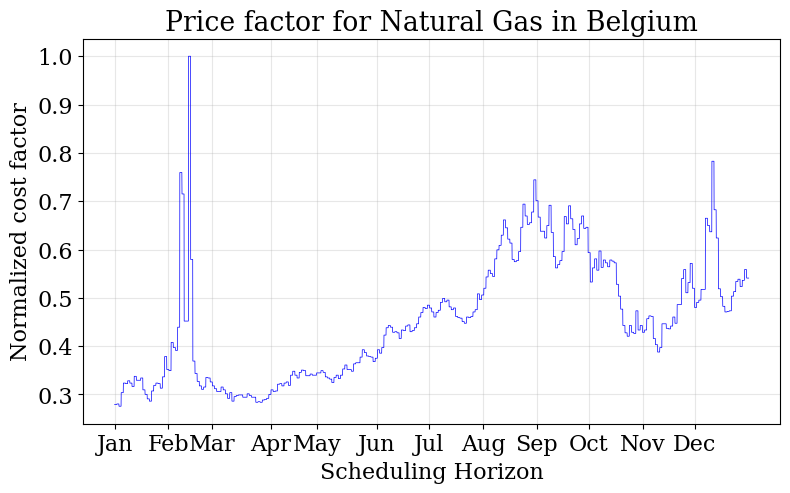

In [31]:

plot_scenario.price_factor(
    scenario=scenario, location=Belgium, resource=NG, fig_size=(9, 5), color='blue')

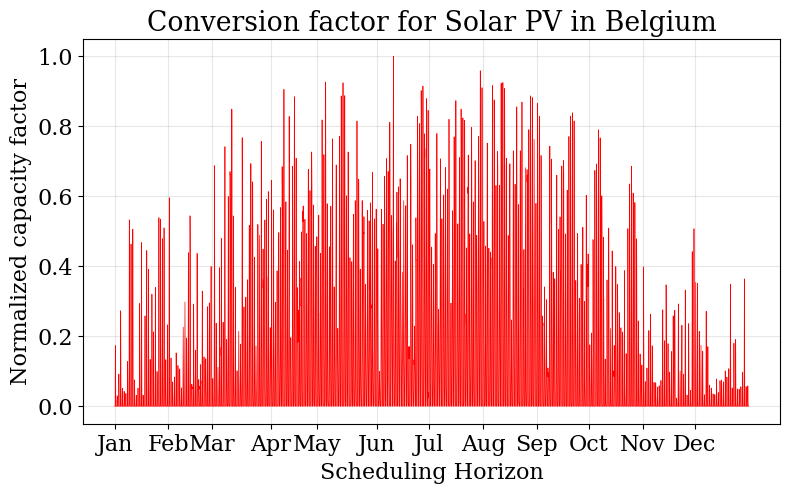

In [32]:
plot_scenario.capacity_factor(
    scenario=scenario, location=Belgium, process=PV, fig_size=(9, 5), color='red')

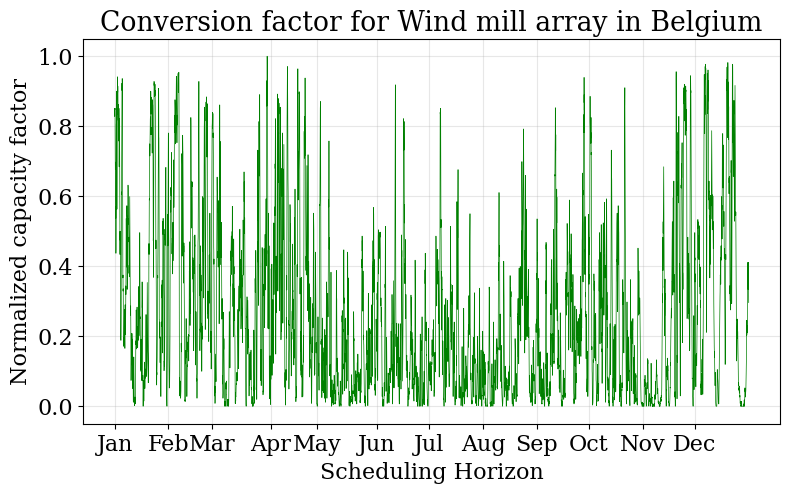

In [33]:
plot_scenario.capacity_factor(
    scenario=scenario, location=Belgium, process=WF, fig_size=(9, 5), color='green')

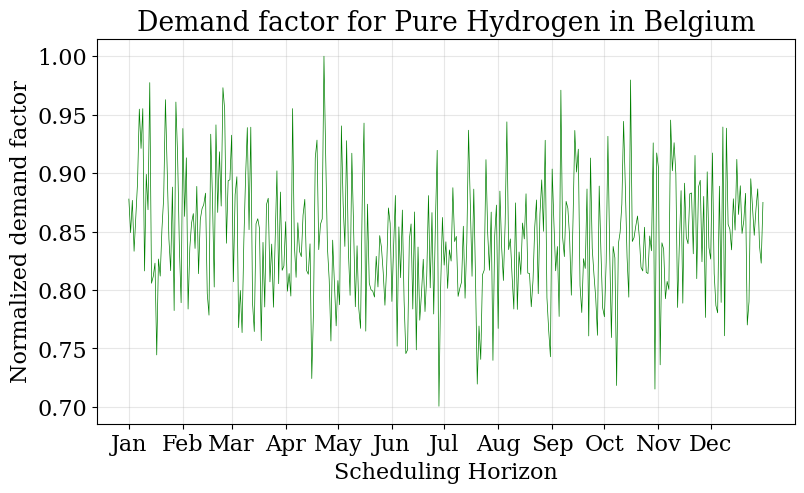

In [34]:
plot_scenario.demand_factor(
    scenario=scenario, location=Belgium, resource=H2Pure, fig_size=(9, 5), color='green')

## Formulate MILP

Here we formulate two milps which differ only in their objectives.

For maximizing the discharge of a particular resource, use the objective MAX_DISCHARGE, the objective resource also needs to be specified.

Similarly the discharge can also be minimized using MIN_DISCHARGE. This can be used with a demand for another resource being set. For example, minimizing the discharge of carbon dioxide while meeting a hydrogen demand.

The second MILP, minimized the cost while meeting a varying demand for power

In [35]:
#, Constraints.MODE

milp_cost = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.NETWORK, Constraints.PRODUCTION,
                      Constraints.RESOURCE_BALANCE, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.COST, demand_sign= 'eq')
#_W_DEMAND_PENALTY
# milp_cost = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.NETWORK, Constraints.PRODUCTION,
#                       Constraints.RESOURCE_BALANCE, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.COST_W_DEMAND_PENALTY)
# #, demand_sign = 'eq')

constraint process capex
constraint process fopex
constraint process vopex
constraint storage capex
constraint process incidental
constraint location capex
constraint storage cost
constraint storage cost location
constraint storage cost network
constraint global warming potential resource
constraint global warming potential resource consumption
constraint global warming potential resource discharge
constraint global warming potential location
constraint global warming potential network
constraint production mode
constraint inventory balance
constraint inventory network
constraint storage facility
constraint production facility
constraint min production facility
constraint min storage facility
constraint demand
objective cost


In [36]:
# # model.component

# from pyomo.environ import ConstraintList
# milp_cost.cons1 = ConstraintList()
# for i in scales.scale_iter(2):
#     milp_cost.cons1.add(expr = milp_cost.P['HO', 'SMR', *i] >= 1000)

In [37]:
# from pyomo.environ import Var, Binary, ConstraintList


# milp_cost.cons2 = ConstraintList()
# for i in scales.scale_iter(2):
#     if i != (0,0,0):
#         milp_cost.cons2.add(expr = milp_cost.P['BG', 'SMR', *i] - milp_cost.P['BG', 'SMR', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.05*milp_cost.Cap_P['BG','SMR', i[0]])
#         # milp_cost.cons2.add(expr = milp_cost.P['HO', 'SMR', *i] - milp_cost.P['HO', 'SMR', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.05*milp_cost.Cap_P['HO','SMR', i[0]])

# milp_cost.cons3 = ConstraintList()
# for i in scales.scale_iter(2):
#     if i != (0,0,0):
#         milp_cost.cons3.add(expr = milp_cost.P['BG', 'SMR', *i] - milp_cost.P['BG', 'SMR', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] >= -0.05*milp_cost.Cap_P['BG','SMR', i[0]])

# '''ATR Constraints'''

# milp_cost.cons4 = ConstraintList()
# for i in scales.scale_iter(2):
#     if i != (0,0,0):
#         milp_cost.cons4.add(expr = milp_cost.P['BG', 'ATR_CCS_R', *i] - milp_cost.P['BG', 'ATR_CCS_R', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.1*milp_cost.Cap_P['BG','ATR_CCS_R', i[0]])

# milp_cost.cons5 = ConstraintList()
# for i in scales.scale_iter(2):
#     if i != (0,0,0):
#         milp_cost.cons5.add(expr = milp_cost.P['BG', 'ATR_CCS_R', *i] - milp_cost.P['BG', 'ATR_CCS_R', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] >= -0.1*milp_cost.Cap_P['BG','ATR_CCS_R', i[0]])


# milp_cost.cons8 = ConstraintList()
# for i in scales.scale_iter(2):
#     if i != (0,0,0):
#         milp_cost.cons8.add(expr = milp_cost.P['BG', 'ATR_CCS_R_OC', *i] - milp_cost.P['BG', 'ATR_CCS_R_OC', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.1*milp_cost.Cap_P['BG','ATR_CCS_R_OC', i[0]])

# milp_cost.cons9 = ConstraintList()
# for i in scales.scale_iter(2):
#     if i != (0,0,0):
#         milp_cost.cons9.add(expr = milp_cost.P['BG', 'ATR_CCS_R_OC', *i] - milp_cost.P['BG', 'ATR_CCS_R_OC', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] >= -0.1*milp_cost.Cap_P['BG','ATR_CCS_R_OC', i[0]])  


# milp_cost.cons10 = ConstraintList()
# for i in scales.scale_iter(2):
#     #if i != (0,0):
#     milp_cost.cons10.add(expr = milp_cost.P['BG', 'SMR', *i] >= 0.3*milp_cost.Cap_P['BG','SMR', i[0]]) #30% of max production rate 6000 * milp_cost.on_smr[i]

# milp_cost.cons11 = ConstraintList()
# for i in scales.scale_iter(2):
#     #if i != (0,0):
#     milp_cost.cons11.add(expr = milp_cost.P['BG', 'ATR_CCS_R', *i] >= 0.2*milp_cost.Cap_P['BG','ATR_CCS_R', i[0]]) #20% of max production rate
    
# milp_cost.cons13 = ConstraintList()
# for i in scales.scale_iter(2):
#     #if i != (0,0):
#     milp_cost.cons13.add(expr = milp_cost.P['BG', 'ATR_CCS_R_OC', *i] >= 0.2*milp_cost.Cap_P['BG','ATR_CCS_R_OC', i[0]]) #20% of max production rate

#     # For SMR
# milp_cost.cons14 = ConstraintList()
# for i in scales.scale_iter(2):
#     #if i != (0, 0):
#     # Force production to zero if the system is off (on_smr == 0)
#     milp_cost.cons14.add(expr = milp_cost.P['BG', 'SMR', *i] <=milp_cost.Cap_P['BG','SMR', i[0]])

# # For ATR_CCS_R
# milp_cost.cons15 = ConstraintList()
# for i in scales.scale_iter(2):
#     #if i != (0, 0):
#     # Force production to zero if the system is off (on_atr_ccs_r == 0)
#     milp_cost.cons15.add(expr = milp_cost.P['BG', 'ATR_CCS_R', *i] <= milp_cost.Cap_P['BG','ATR_CCS_R', i[0]])

# # For ATR_CCS_R_OC
# milp_cost.cons17 = ConstraintList()
# for i in scales.scale_iter(2):
#     #if i != (0, 0):
#     # Force production to zero if the system is off (on_atr_ccs_r_oc == 0)
#     milp_cost.cons17.add(expr = milp_cost.P['BG', 'ATR_CCS_R_OC', *i] <= milp_cost.Cap_P['BG','ATR_CCS_R_OC', i[0]])

#--------------------------------------------------------------------------------------------------------------------------
#New

from pyomo.environ import Var, Binary, ConstraintList

# --- Helper to get prev/next index safely ---
all_indices = scales.scale_iter(2)
# 0.05
milp_cost.cons2 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_cost.cons2.add(expr = milp_cost.P['BG', 'SMR', *i] - milp_cost.P['BG', 'SMR', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.05*milp_cost.Cap_P['BG','SMR', i[0]])

milp_cost.cons3 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_cost.cons3.add(expr = milp_cost.P['BG', 'SMR', *i] - milp_cost.P['BG', 'SMR', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] >= -0.05*milp_cost.Cap_P['BG','SMR', i[0]])

'''ATR Constraints'''
#0.1
milp_cost.cons4 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_cost.cons4.add(expr = milp_cost.P['BG', 'ATR_CCS_R', *i] - milp_cost.P['BG', 'ATR_CCS_R', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.1*milp_cost.Cap_P['BG','ATR_CCS_R', i[0]])

milp_cost.cons5 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_cost.cons5.add(expr = milp_cost.P['BG', 'ATR_CCS_R', *i] - milp_cost.P['BG', 'ATR_CCS_R', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] >= -0.1*milp_cost.Cap_P['BG','ATR_CCS_R', i[0]])


milp_cost.cons8 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_cost.cons8.add(expr = milp_cost.P['BG', 'ATR_CCS_R_OC', *i] - milp_cost.P['BG', 'ATR_CCS_R_OC', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.1*milp_cost.Cap_P['BG','ATR_CCS_R_OC', i[0]])

milp_cost.cons9 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_cost.cons9.add(expr = milp_cost.P['BG', 'ATR_CCS_R_OC', *i] - milp_cost.P['BG', 'ATR_CCS_R_OC', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] >= -0.1*milp_cost.Cap_P['BG','ATR_CCS_R_OC', i[0]])  


milp_cost.cons10 = ConstraintList()
for i in scales.scale_iter(2):
    milp_cost.cons10.add(expr = milp_cost.P['BG', 'SMR', *i] >= 0.3*milp_cost.Cap_P['BG','SMR', i[0]])

milp_cost.cons11 = ConstraintList()
for i in scales.scale_iter(2):
    milp_cost.cons11.add(expr = milp_cost.P['BG', 'ATR_CCS_R', *i] >= 0.2*milp_cost.Cap_P['BG','ATR_CCS_R', i[0]])
    
milp_cost.cons13 = ConstraintList()
for i in scales.scale_iter(2):
    milp_cost.cons13.add(expr = milp_cost.P['BG', 'ATR_CCS_R_OC', *i] >= 0.2*milp_cost.Cap_P['BG','ATR_CCS_R_OC', i[0]])

milp_cost.cons14 = ConstraintList()
for i in scales.scale_iter(2):
    milp_cost.cons14.add(expr = milp_cost.P['BG', 'SMR', *i] <= milp_cost.Cap_P['BG','SMR', i[0]])

milp_cost.cons15 = ConstraintList()
for i in scales.scale_iter(2):
    milp_cost.cons15.add(expr = milp_cost.P['BG', 'ATR_CCS_R', *i] <= milp_cost.Cap_P['BG','ATR_CCS_R', i[0]])

milp_cost.cons17 = ConstraintList()
for i in scales.scale_iter(2):
    milp_cost.cons17.add(expr = milp_cost.P['BG', 'ATR_CCS_R_OC', *i] <= milp_cost.Cap_P['BG','ATR_CCS_R_OC', i[0]])


In [38]:

import time

start_time = time.perf_counter()

results_cost = solve(
    scenario=scenario,
    instance=milp_cost,
    solver="gurobi",
    name="res_cost",
    print_solversteps=True,
    saveformat=".pkl"
)

elapsed_time = time.perf_counter() - start_time

print(f"Cost-minimization runtime: {elapsed_time:.2f} seconds")
print(f"Cost-minimization runtime: {elapsed_time / 60:.2f} minutes")


# results_cost = solve(scenario=scenario, instance=milp_cost,
#                      solver='gurobi', name="res_cost", print_solversteps=True, saveformat = '.pkl')


Set parameter OutputFlag to value 1
Set parameter QCPDual to value 1
Gurobi Optimizer version 12.0.1 build v12.0.1rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: 13th Gen Intel(R) Core(TM) i7-13700, instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 24 logical processors, using up to 24 threads

Non-default parameters:
QCPDual  1

Optimize a model with 1349614 rows, 7271080 columns and 3552273 nonzeros
Model fingerprint: 0x18b8303a
Variable types: 7271067 continuous, 13 integer (13 binary)
Coefficient statistics:
  Matrix range     [3e-06, 1e+08]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [6e+02, 1e+08]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 1108152 rows and 7152613 columns
Presolve time: 0.74s
Presolved: 241462 rows, 118467 columns, 670713 nonzeros
Variable types: 118451 continuous, 16 integer (9 binary)
Performing another presolve...
Presol

In [39]:
#plot_results.schedule(results = results_cost, y_axis= 'P', component = 'SMR', location='BG')

In [40]:
#plot_results.schedule(results = results_cost, y_axis= 'P', component = 'Grid', location='BG')

In [41]:
results_cost.output['objective']

261509674.8160855

In [42]:
results_cost.output['global_warming_potential_location']

{('BG', 0): 1426150963.289314}

In [43]:
results_cost.output['global_warming_potential_resource']

{('BG', 'CO2 Captured', 0, 0, 0): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 1): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 2): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 3): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 4): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 5): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 6): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 7): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 8): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 9): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 10): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 11): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 12): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 13): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 14): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 15): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 16): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 17): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 18): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 19): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 20): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 21): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 22): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 23): 0.0,
 ('BG', 'CO2 Captured', 0, 1, 0): 0.0,
 ('BG', 'CO

In [44]:
results_cost.output['X_P']

{('BG', 'ATR_CCS_R', 0): 0.0,
 ('BG', 'ATR_CCS_R_OC', 0): 0.0,
 ('BG', 'AWE', 0): 0.0,
 ('BG', 'D1', 0): 1.0,
 ('BG', 'D2', 0): 1.0,
 ('BG', 'D3', 0): 1.0,
 ('BG', 'D4', 0): 1.0,
 ('BG', 'Grid', 0): 1.0,
 ('BG', 'PEM', 0): -0.0,
 ('BG', 'PV', 0): 1.0,
 ('BG', 'SMR', 0): 1.0,
 ('BG', 'SMRCCS', 0): -0.0,
 ('BG', 'WF', 0): 1.0}

In [45]:
# gwp = results_cost.output['global_warming_potential_resource']

# # Convert dict -> rows
# df = pd.DataFrame(
#     [(k[0], k[1], k[2], k[3], k[4], v) for k, v in gwp.items()],
#     columns=["location", "emission", "idx_2", "idx_3", "idx_4", "GWP"]
# )

# df.to_excel("gwp_resource.xlsx", index=False)

In [46]:
milp_cost.Cap_P.pprint()

Cap_P : Process Capacity
    Size=13, Index=locations*processes*scales_network
    Key                       : Lower : Value            : Upper : Fixed : Stale : Domain
       ('BG', 'ATR_CCS_R', 0) :     0 :              0.0 :  None : False : False : NonNegativeReals
    ('BG', 'ATR_CCS_R_OC', 0) :     0 :              0.0 :  None : False : False : NonNegativeReals
             ('BG', 'AWE', 0) :     0 :              0.0 :  None : False : False : NonNegativeReals
              ('BG', 'D1', 0) :     0 :      100000000.0 :  None : False : False : NonNegativeReals
              ('BG', 'D2', 0) :     0 :      100000000.0 :  None : False : False : NonNegativeReals
              ('BG', 'D3', 0) :     0 :      100000000.0 :  None : False : False : NonNegativeReals
              ('BG', 'D4', 0) :     0 :      100000000.0 :  None : False : False : NonNegativeReals
            ('BG', 'Grid', 0) :     0 :      100000000.0 :  None : False : False : NonNegativeReals
             ('BG', 'PEM', 0) :

In [47]:
x = results_cost.output['P']

In [48]:
y = results_cost.output['global_warming_potential_resource']

In [49]:
results_cost.output['objective']

261509674.8160855

In [50]:
results_cost.output['global_warming_potential_resource']

{('BG', 'CO2 Captured', 0, 0, 0): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 1): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 2): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 3): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 4): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 5): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 6): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 7): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 8): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 9): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 10): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 11): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 12): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 13): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 14): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 15): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 16): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 17): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 18): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 19): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 20): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 21): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 22): 0.0,
 ('BG', 'CO2 Captured', 0, 0, 23): 0.0,
 ('BG', 'CO2 Captured', 0, 1, 0): 0.0,
 ('BG', 'CO

## Graphing Emission Production


In [51]:
# import pandas as pd
# import matplotlib.pyplot as plt
# import matplotlib.dates as mdates
# from datetime import datetime, timedelta

# # Build the hourly time index
# time_labels = [datetime(2024, 1, 1) + timedelta(days=d, hours=h)
#                for d in range(365) for h in range(24)]

# # Build series (hourly)
# #s1 = [y['BG', 'CO2 to Stack', 0, d, h] for d in range(365) for h in range(24)]
# s2 = [y['BG', 'GridPower',    0, d, h] for d in range(365) for h in range(24)]
# #s3 = [y['BG', 'Natural Gas',  0, d, h] for d in range(365) for h in range(24)]

# df = pd.DataFrame(
#     {"Scope 1": s1, "Scope 2": s2, "Scope 3": s3},
#     index=pd.to_datetime(time_labels)
# )

# # Choose ONE:
# daily = df.resample("D").sum()   # daily total GWP (recommended if values are kg/h)
# # daily = df.resample("D").mean()  # daily average GWP

# plt.figure(figsize=(10,5))
# #plt.plot(daily.index, daily["Scope 1"], label="Scope 1")
# plt.plot(daily.index, daily["Scope 2"], label="Scope 2")
# #plt.plot(daily.index, daily["Scope 3"], label="Scope 3")

# plt.xlabel("Time")
# plt.ylabel("Daily Global Warming Potential [kg CO$_2$]")
# plt.ticklabel_format(style='sci', axis='y')

# ax = plt.gca()
# ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
# ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
# plt.grid(True, linestyle="--", linewidth=0.5, alpha=0.3)
# plt.legend()
# plt.tight_layout()
# plt.show()


In [52]:
# # total annual Scope 2 (GridPower) emissions
# annual_scope2 = df["Scope 2"].sum()

# print(f"Annual Scope 2 (GridPower) emissions: {annual_scope2:,.2f} kg CO2")



In [53]:
# import matplotlib.pyplot as plt

# # annual totals across all hours
# totals = df.sum()   # sums each column over the full index

# plt.figure(figsize=(6,4))
# plt.bar(totals.index, totals.values)
# plt.ylabel("Total Global Warming Potential [kg CO$_2$]")
# plt.tight_layout()
# plt.show()


In [54]:
# totals = df.sum()
# print(totals)

In [55]:
# import matplotlib.pyplot as plt
# import matplotlib.dates as mdates
# from datetime import datetime, timedelta

# # Generate time labels
# time_labels = [datetime(2024, 1, 1) + timedelta(days=j, hours=i) for j in range(0,365) for i in range(24)]
# #SMRplot = [x['BG', 'SMR', day, hour] for day in range(0,1) for hour in range(24)]
# #345,348

# #plt.fill_between(time_labels, SMRplot, color= 'maroon', alpha=0.1)

# plt.plot(time_labels, [y['BG', 'CO2 to Stack', 0, day, hour] for day in range(0,365) for hour in range(24)], color='maroon', label="Scope 1")
# plt.plot(time_labels, [y['BG', 'GridPower', 0, day, hour] for day in range(0,365) for hour in range(24)], color='g', label="Scope 2")
# plt.plot(time_labels, [y['BG', 'Natural Gas', 0, day, hour] for day in range(0,365) for hour in range(24)], color='b', label="Scope 3")
# #plt.plot(time_labels, SMRplot, color='maroon', linestyle='--', label = 'SMR')#, label = "Hydrogen production rate")

# # Labeling axes
# plt.xlabel('Time', fontsize = 14)
# plt.ylabel('Hourly Global Warming Potential [kg CO2]', fontsize = 14)

# # Format the y-axis in scientific notation
# plt.ticklabel_format(style='sci', axis='y')  

# # Set limits for y and x axes
# plt.ylim(bottom=0)
# plt.xlim([time_labels[0], time_labels[-1]])

# # Set custom time labels for the x-axis
# plt.gca().xaxis.set_major_locator(mdates.HourLocator(interval=8))  # Show one tick per month
# plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %d %H:%M'))  # Format as 'Jan 2024', 'Feb 2024', etc.  %Y
# plt.xticks(rotation=45)
# '%b %d %H:%M'
# # Add grid
# plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)

# # Display legend
# plt.legend(fontsize = 10)

# # Show the plot
# plt.show()

In [56]:
import gurobipy as gp
print(gp.gurobi.version())

(12, 0, 1)


## Graphing Hydrogen Production

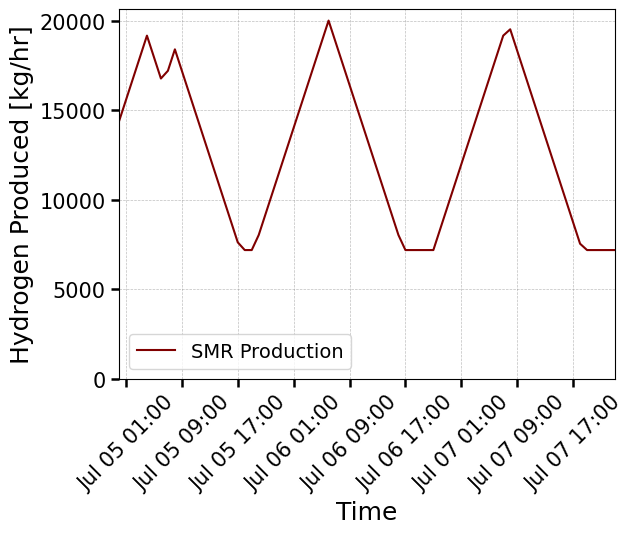

In [57]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta

# Generate time labels
time_labels = [datetime(2024, 1, 1) + timedelta(days=j, hours=i) for j in range(186,189) for i in range(24)]
#SMRplot = [x['BG', 'SMR', day, hour] for day in range(0,1) for hour in range(24)]
#345,348

#plt.fill_between(time_labels, SMRplot, color= 'maroon', alpha=0.1)

plt.plot(time_labels, [x['BG', 'SMR', 0, day, hour] for day in range(186,189) for hour in range(24)], color='maroon', label="SMR Production")
#plt.plot(time_labels, SMRplot, color='maroon', linestyle='--', label = 'SMR')#, label = "Hydrogen production rate")

# Labeling axes
plt.xlabel('Time', fontsize = 14)
plt.ylabel('Hourly Hydrogen Production [kg]', fontsize = 14)

# Format the y-axis in scientific notation
plt.ticklabel_format(style='sci', axis='y')  

# Set limits for y and x axes
plt.ylim(bottom=0)
plt.xlim([time_labels[0], time_labels[-1]])

# Set custom time labels for the x-axis
plt.gca().xaxis.set_major_locator(mdates.HourLocator(interval=8))  # Show one tick per month
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %d %H:%M'))  # Format as 'Jan 2024', 'Feb 2024', etc.  %Y
plt.xticks(rotation=45)
'%b %d %H:%M'
# Add grid
plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)


# )

# Axis labels
plt.xlabel('Time', fontsize=18)
plt.ylabel('Hydrogen Produced [kg/hr]', fontsize=18)

# Tick labels
plt.tick_params(axis='both', which='major', labelsize=15)

# Make scientific notation exponent larger
plt.gca().yaxis.get_offset_text().set_fontsize(14)

plt.tick_params(
    axis='both',
    which='major',
    width=1.8,      # thickness of tick marks
    length=6        # length of ticks
)
# Display legend
plt.legend(fontsize = 14)

# Show the plot
plt.show()

## Graphing Grid Usage

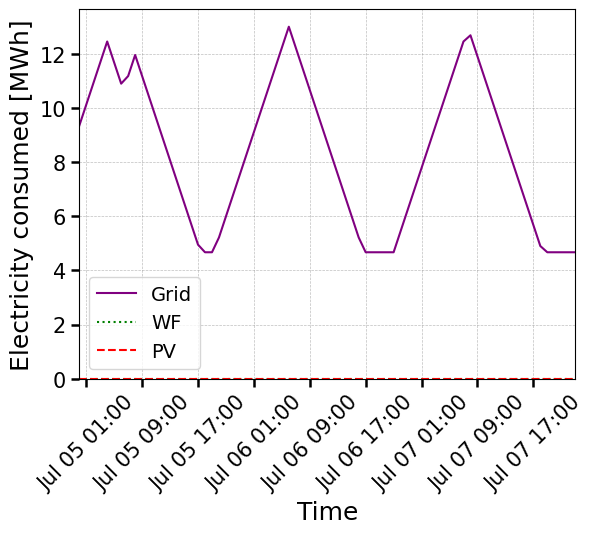

In [58]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta

# Generate time labels
time_labels = [datetime(2024, 1, 1) + timedelta(days=j, hours=i) for j in range(186,189) for i in range(24)]
#SMRplot = [x['BG', 'Grid', day, hour] for day in range(0,1) for hour in range(24)]


#plt.fill_between(time_labels, SMRplot, color= 'maroon', alpha=0.1)

#plt.plot(time_labels, SMRplot, color='maroon', linestyle='--', label = 'SMR')#, label = "Hydrogen production rate")
plt.plot(time_labels, [x['BG', 'Grid',0, day, hour] for day in range(186,189) for hour in range(24)], color='purple', label="Grid")
plt.plot(time_labels, [x['BG', 'WF',0, day, hour] for day in range(186,189) for hour in range(24)], color='g', linestyle=':', label="WF")
plt.plot(time_labels, [x['BG', 'PV',0, day, hour] for day in range(186,189) for hour in range(24)], color='red', linestyle='--', label="PV")

# Labeling axes
# plt.xlabel('Time', fontsize = 14)
# plt.ylabel('Total Electricity Consumed [MWh]', fontsize = 14)

# Format the y-axis in scientific notation
plt.ticklabel_format(style='sci', axis='y')  

# Set limits for y and x axes
plt.ylim(bottom=0)
plt.xlim([time_labels[0], time_labels[-1]])

# Set custom time labels for the x-axis
plt.gca().xaxis.set_major_locator(mdates.HourLocator(interval=8))  # Show one tick per month
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %d %H:%M'))  # Format as 'Jan 2024', 'Feb 2024', etc.  %Y
plt.xticks(rotation=45)

# Add grid
plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)


# Axis labels
plt.xlabel('Time', fontsize=18)
plt.ylabel('Electricity consumed [MWh]', fontsize=18)

# Tick labels
plt.tick_params(axis='both', which='major', labelsize=15)

# Make scientific notation exponent larger
plt.gca().yaxis.get_offset_text().set_fontsize(14)

plt.tick_params(
    axis='both',
    which='major',
    width=1.8,      # thickness of tick marks
    length=6        # length of ticks
)
# Display legend
plt.legend(fontsize = 14)
# # Display legend
# plt.legend(fontsize = 10)

# Show the plot
plt.show()

## For Minimizing GWP

## For Emission Reduction Scenarios

In [59]:
# from energiapy.model.constraints.emission import constraint_global_warming_potential_network_reduction
# from pyomo.environ import Var, Binary

# def modeler(gwp_pct: float):
#     gwp_eval = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION, Constraints.NETWORK,
#                         Constraints.RESOURCE_BALANCE, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.COST, demand_sign = 'geq')
#     gwp_eval.cons2 = ConstraintList()
#     gwp_eval.cons3 = ConstraintList()
#     gwp_eval.cons4 = ConstraintList()
#     gwp_eval.cons5 = ConstraintList()
#     gwp_eval.cons8 = ConstraintList()
#     gwp_eval.cons9 = ConstraintList()
#     gwp_eval.cons10 = ConstraintList()
#     gwp_eval.cons11 = ConstraintList()
#     gwp_eval.cons13 = ConstraintList()
#     gwp_eval.cons14 = ConstraintList()
#     gwp_eval.cons15 = ConstraintList()
#     gwp_eval.cons17 = ConstraintList()

#     for i in scales.scale_iter(2):
#         gwp_eval.cons10.add(expr = gwp_eval.P['BG', 'SMR', *i] >= 0.3*gwp_eval.Cap_P['BG','SMR', i[0]]) #30% of max production rate 6000 * milp_cost.on_smr[i]
#         gwp_eval.cons11.add(expr = gwp_eval.P['BG', 'ATR_CCS_R', *i] >= 0.2*gwp_eval.Cap_P['BG','ATR_CCS_R', i[0]]) #20% of max production rate
#         gwp_eval.cons13.add(expr = gwp_eval.P['BG', 'ATR_CCS_R_OC', *i] >= 0.2*gwp_eval.Cap_P['BG','ATR_CCS_R_OC', i[0]]) #20% of max production rate
#         gwp_eval.cons14.add(expr = gwp_eval.P['BG', 'SMR', *i] <=gwp_eval.Cap_P['BG','SMR', i[0]])
#         gwp_eval.cons15.add(expr = gwp_eval.P['BG', 'ATR_CCS_R', *i] <= gwp_eval.Cap_P['BG','ATR_CCS_R', i[0]])
#         gwp_eval.cons17.add(expr = gwp_eval.P['BG', 'ATR_CCS_R_OC', *i] <= gwp_eval.Cap_P['BG','ATR_CCS_R_OC', i[0]])
#         if i != (0,0,0):
#             gwp_eval.cons2.add(expr = gwp_eval.P['BG', 'SMR', *i] - gwp_eval.P['BG', 'SMR', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.05*gwp_eval.Cap_P['BG','SMR', i[0]])
#             gwp_eval.cons3.add(expr = gwp_eval.P['BG', 'SMR', *i] - gwp_eval.P['BG', 'SMR', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] >= -0.05*gwp_eval.Cap_P['BG','SMR', i[0]])
#             gwp_eval.cons4.add(expr = gwp_eval.P['BG', 'ATR_CCS_R', *i] - gwp_eval.P['BG', 'ATR_CCS_R', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.1*gwp_eval.Cap_P['BG','ATR_CCS_R', i[0]])
#             gwp_eval.cons5.add(expr = gwp_eval.P['BG', 'ATR_CCS_R', *i] - gwp_eval.P['BG', 'ATR_CCS_R', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] >= -0.1*gwp_eval.Cap_P['BG','ATR_CCS_R', i[0]])
#             gwp_eval.cons8.add(expr = gwp_eval.P['BG', 'ATR_CCS_R_OC', *i] - gwp_eval.P['BG', 'ATR_CCS_R_OC', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.1*gwp_eval.Cap_P['BG','ATR_CCS_R_OC', i[0]])
#             gwp_eval.cons9.add(expr = gwp_eval.P['BG', 'ATR_CCS_R_OC', *i] - gwp_eval.P['BG', 'ATR_CCS_R_OC', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] >= -0.1*gwp_eval.Cap_P['BG','ATR_CCS_R_OC', i[0]])


#     constraint_global_warming_potential_network_reduction(instance= gwp_eval, network_scale_level = 0, gwp_reduction_pct = gwp_pct, gwp = results_cost.output['global_warming_potential_network'][0])
    
#     return gwp_eval

## Newly formulated constraints

In [60]:
from energiapy.model.constraints.emission import constraint_global_warming_potential_network_reduction
from pyomo.environ import Var, Binary

# Smoothing parameters - tune these to control peak dampening
RAMP_SMR     = 0.05
RAMP_ATR     = 0.1
RAMP_ATR_OC  = 0.1
C2_SMR       = 0.008
C2_ATR       = 0.018
C2_ATR_OC    = 0.018

def modeler(gwp_pct: float):
    gwp_eval = formulate(
        scenario=scenario,
        constraints={
            Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION,
            Constraints.NETWORK, Constraints.RESOURCE_BALANCE,
            Constraints.DEMAND, Constraints.EMISSION
        },
        objective=Objective.COST,
        demand_sign='geq'
    )

# ,
#         'cons_smooth_smr_up', 'cons_smooth_smr_dn',
#         'cons_smooth_atr_up', 'cons_smooth_atr_dn',
#         'cons_smooth_atr_oc_up', 'cons_smooth_atr_oc_dn'

    # --- Declare all constraint lists ---
    for name in [
        'cons2', 'cons3', 'cons4', 'cons5', 'cons8', 'cons9',
        'cons10', 'cons11', 'cons13', 'cons14', 'cons15', 'cons17',
    ]:
        setattr(gwp_eval, name, ConstraintList())

    # Pre-compute index list once
    _idx = scales.scale_iter(2)

    for i in _idx:
        # --- Min/max production bounds ---
        gwp_eval.cons10.add(expr=gwp_eval.P['BG', 'SMR', *i]          >= 0.3 * gwp_eval.Cap_P['BG', 'SMR', i[0]])
        gwp_eval.cons11.add(expr=gwp_eval.P['BG', 'ATR_CCS_R', *i]    >= 0.2 * gwp_eval.Cap_P['BG', 'ATR_CCS_R', i[0]])
        gwp_eval.cons13.add(expr=gwp_eval.P['BG', 'ATR_CCS_R_OC', *i] >= 0.2 * gwp_eval.Cap_P['BG', 'ATR_CCS_R_OC', i[0]])
        gwp_eval.cons14.add(expr=gwp_eval.P['BG', 'SMR', *i]          <= gwp_eval.Cap_P['BG', 'SMR', i[0]])
        gwp_eval.cons15.add(expr=gwp_eval.P['BG', 'ATR_CCS_R', *i]    <= gwp_eval.Cap_P['BG', 'ATR_CCS_R', i[0]])
        gwp_eval.cons17.add(expr=gwp_eval.P['BG', 'ATR_CCS_R_OC', *i] <= gwp_eval.Cap_P['BG', 'ATR_CCS_R_OC', i[0]])

        if i != (0, 0, 0):
            i_prev = _idx[_idx.index(i) - 1]

            # --- First-difference ramp constraints ---
            gwp_eval.cons2.add(expr=gwp_eval.P['BG', 'SMR', *i]          - gwp_eval.P['BG', 'SMR', *i_prev]          <= RAMP_SMR    * gwp_eval.Cap_P['BG', 'SMR', i[0]])
            gwp_eval.cons3.add(expr=gwp_eval.P['BG', 'SMR', *i]          - gwp_eval.P['BG', 'SMR', *i_prev]          >= -RAMP_SMR   * gwp_eval.Cap_P['BG', 'SMR', i[0]])
            gwp_eval.cons4.add(expr=gwp_eval.P['BG', 'ATR_CCS_R', *i]    - gwp_eval.P['BG', 'ATR_CCS_R', *i_prev]    <= RAMP_ATR    * gwp_eval.Cap_P['BG', 'ATR_CCS_R', i[0]])
            gwp_eval.cons5.add(expr=gwp_eval.P['BG', 'ATR_CCS_R', *i]    - gwp_eval.P['BG', 'ATR_CCS_R', *i_prev]    >= -RAMP_ATR   * gwp_eval.Cap_P['BG', 'ATR_CCS_R', i[0]])
            gwp_eval.cons8.add(expr=gwp_eval.P['BG', 'ATR_CCS_R_OC', *i] - gwp_eval.P['BG', 'ATR_CCS_R_OC', *i_prev] <= RAMP_ATR_OC  * gwp_eval.Cap_P['BG', 'ATR_CCS_R_OC', i[0]])
            gwp_eval.cons9.add(expr=gwp_eval.P['BG', 'ATR_CCS_R_OC', *i] - gwp_eval.P['BG', 'ATR_CCS_R_OC', *i_prev] >= -RAMP_ATR_OC * gwp_eval.Cap_P['BG', 'ATR_CCS_R_OC', i[0]])

    # # --- Second-difference (curvature) smoothing constraints ---
    # for k in range(1, len(_idx) - 1):
    #     i_prev, i_curr, i_next = _idx[k - 1], _idx[k], _idx[k + 1]

    #     accel_smr = (
    #         gwp_eval.P['BG', 'SMR', *i_next]
    #         - 2 * gwp_eval.P['BG', 'SMR', *i_curr]
    #         + gwp_eval.P['BG', 'SMR', *i_prev]
    #     )
    #     cap_smr = gwp_eval.Cap_P['BG', 'SMR', i_curr[0]]
    #     gwp_eval.cons_smooth_smr_up.add(expr=accel_smr <=  C2_SMR * cap_smr)
    #     gwp_eval.cons_smooth_smr_dn.add(expr=accel_smr >= -C2_SMR * cap_smr)

    #     accel_atr = (
    #         gwp_eval.P['BG', 'ATR_CCS_R', *i_next]
    #         - 2 * gwp_eval.P['BG', 'ATR_CCS_R', *i_curr]
    #         + gwp_eval.P['BG', 'ATR_CCS_R', *i_prev]
    #     )
    #     cap_atr = gwp_eval.Cap_P['BG', 'ATR_CCS_R', i_curr[0]]
    #     gwp_eval.cons_smooth_atr_up.add(expr=accel_atr <=  C2_ATR * cap_atr)
    #     gwp_eval.cons_smooth_atr_dn.add(expr=accel_atr >= -C2_ATR * cap_atr)

    #     accel_atr_oc = (
    #         gwp_eval.P['BG', 'ATR_CCS_R_OC', *i_next]
    #         - 2 * gwp_eval.P['BG', 'ATR_CCS_R_OC', *i_curr]
    #         + gwp_eval.P['BG', 'ATR_CCS_R_OC', *i_prev]
    #     )
    #     cap_atr_oc = gwp_eval.Cap_P['BG', 'ATR_CCS_R_OC', i_curr[0]]
    #     gwp_eval.cons_smooth_atr_oc_up.add(expr=accel_atr_oc <=  C2_ATR_OC * cap_atr_oc)
    #     gwp_eval.cons_smooth_atr_oc_dn.add(expr=accel_atr_oc >= -C2_ATR_OC * cap_atr_oc)

    constraint_global_warming_potential_network_reduction(
        instance=gwp_eval,
        network_scale_level=0,
        gwp_reduction_pct=gwp_pct,
        gwp=results_cost.output['global_warming_potential_network'][0]
    )

    return gwp_eval

## Newly formulated solver

In [61]:
import os
import gc
import time
import pandas as pd

os.makedirs("res_red", exist_ok=True)

def solver(instance, gwp_pct):
    return solve(
        scenario=scenario,
        instance=instance,
        solver="gurobi",
        name=f"res_red/res_red_{gwp_pct}",
        print_solversteps=True,
        saveformat=".pkl"
    )


results = {}
runtime_records = []

overall_start = time.perf_counter()

for i in range(10):
    gwp_pct = (i + 1) * 10

    print(
        f"\nBuilding and solving model {i + 1}/10 "
        f"(GWP reduction = {gwp_pct}%)..."
    )

    # ---------------------------------
    # Measure model-construction time
    # ---------------------------------
    build_start = time.perf_counter()

    instance = modeler(gwp_pct)

    build_time = time.perf_counter() - build_start

    # ---------------------------------
    # Measure solve-call time
    # ---------------------------------
    solve_start = time.perf_counter()

    results[gwp_pct] = solver(instance, gwp_pct)

    solve_time = time.perf_counter() - solve_start

    # Total time for this scenario
    scenario_time = build_time + solve_time

    runtime_records.append({
        "GWP_reduction_percent": gwp_pct,
        "model_build_time_seconds": build_time,
        "solve_call_time_seconds": solve_time,
        "total_scenario_time_seconds": scenario_time,
        "model_build_time_minutes": build_time / 60,
        "solve_call_time_minutes": solve_time / 60,
        "total_scenario_time_minutes": scenario_time / 60
    })

    print(f"Model construction time: {build_time:.2f} seconds")
    print(f"Solve-call time:         {solve_time:.2f} seconds")
    print(f"Total scenario time:     {scenario_time:.2f} seconds")

    # Delete model and release memory
    del instance
    gc.collect()


overall_time = time.perf_counter() - overall_start

# Convert results to a table
runtime_df = pd.DataFrame(runtime_records)

# Save computational-time results
runtime_df.to_excel(
    "epsilon_constraint_computational_times.xlsx",
    index=False
)

runtime_df.to_csv(
    "epsilon_constraint_computational_times.csv",
    index=False
)

print("\nAll models solved.")
print(f"Total measured runtime: {overall_time:.2f} seconds")
print(f"Total measured runtime: {overall_time / 60:.2f} minutes")

print("\nRuntime summary:")
print(runtime_df)


Building and solving model 1/10 (GWP reduction = 10%)...
constraint process capex
constraint process fopex
constraint process vopex
constraint storage capex
constraint process incidental
constraint location capex
constraint storage cost
constraint storage cost location
constraint storage cost network
constraint global warming potential resource
constraint global warming potential resource consumption
constraint global warming potential resource discharge
constraint global warming potential location
constraint global warming potential network
constraint production mode
constraint inventory balance
constraint inventory network
constraint storage facility
constraint production facility
constraint min production facility
constraint min storage facility
constraint demand
objective cost
constraint global warming potential network reduction
Set parameter OutputFlag to value 1
Set parameter QCPDual to value 1
Gurobi Optimizer version 12.0.1 build v12.0.1rc0 (win64 - Windows 11+.0 (26200.2))



## This has gotten too much

In [63]:
import pickle
from pathlib import Path

import pandas as pd


# ─────────────────────────────────────────────────────────────
# User settings
# ─────────────────────────────────────────────────────────────
results_dir = Path("res_red")
out_path = "Test_mean_constant_epsilon_constraint_results_with_penalties.xlsx"

location_filter = "BG"
n_cases = 10

# Each P value for D1-D4 is in kg/h and each model time step is one hour.
# Change this value if your model uses a different time-step duration.
time_step_hours = 1.0

# Ignore very small numerical values returned by the solver.
zero_tolerance = 1e-8

# Demand-penalty definitions.
# Because each process has a 1:1 conversion:
#     D1: DP1 -> H2Pure
#     D2: DP2 -> H2Pure
#     D3: DP3 -> H2Pure
#     D4: DP4 -> H2Pure
# the solved P value for D1-D4 equals the demand deviation in kg/h.
penalty_definitions = {
    "D1": {
        "penalty_resource": "DP1",
        "penalty_rate_USD_per_kg": 10.0,
        "bucket_max_kg_per_hr": 750.0,
        "description": "First demand-deviation bucket",
    },
    "D2": {
        "penalty_resource": "DP2",
        "penalty_rate_USD_per_kg": 25.0,
        "bucket_max_kg_per_hr": 2250.0,
        "description": "Second demand-deviation bucket",
    },
    "D3": {
        "penalty_resource": "DP3",
        "penalty_rate_USD_per_kg": 50.0,
        "bucket_max_kg_per_hr": 4000.0,
        "description": "Third demand-deviation bucket",
    },
    "D4": {
        "penalty_resource": "DP4",
        "penalty_rate_USD_per_kg": 115.0,
        "bucket_max_kg_per_hr": 5250.0,
        "description": "Fourth demand-deviation bucket",
    },
}

production_processes_to_track = {
    "PV",
    "WF",
    "Grid",
    "D1",
    "D2",
    "D3",
    "D4",
}


# ─────────────────────────────────────────────────────────────
# Helper functions
# ─────────────────────────────────────────────────────────────
def get_output(res):
    """
    Handle different pickle formats:
      1. res.output
      2. res['output']
      3. res is already the output dictionary
    """
    if hasattr(res, "output"):
        return res.output

    if isinstance(res, dict):
        if "output" in res:
            return res["output"]
        return res

    raise TypeError(f"Unknown result format: {type(res)}")


def is_optimal(output):
    """Return True when the saved result has an optimal termination."""
    term = output.get("termination", None)
    if term is None:
        return False
    return str(term).strip().lower() == "optimal"


def safe_get(dictionary, key, default=None):
    """Safely retrieve values from dictionaries that may use tuple keys."""
    if not isinstance(dictionary, dict):
        return default
    return dictionary.get(key, default)


def find_result_file(gwp_pct):
    """
    Find a saved result file using either naming convention.

    Current solver convention:
        res_red_10.pkl, res_red_20.pkl, ..., res_red_100.pkl

    Older convention:
        res_red_0.pkl, res_red_1.pkl, ..., res_red_9.pkl
    """
    old_index = (gwp_pct // 10) - 1

    candidates = [
        results_dir / f"res_red_{gwp_pct}.pkl",
        results_dir / f"res_red_{old_index}.pkl",
    ]

    for candidate in candidates:
        if candidate.exists():
            return candidate

    return None


def make_reduction_columns(df):
    """Rename pivot-table columns as 10pct_reduction, etc."""
    if df.empty:
        return df

    df.columns = [f"{int(c)}pct_reduction" for c in df.columns]
    return df


# ─────────────────────────────────────────────────────────────
# 1. Load all solved results
# ─────────────────────────────────────────────────────────────
# The dictionary is keyed directly by GWP-reduction percentage.
loaded = {}
loaded_file_records = []

for gwp_pct in range(10, (n_cases + 1) * 10, 10):
    path = find_result_file(gwp_pct)

    if path is None:
        print(
            f"[!] Missing result for {gwp_pct}% reduction. "
            f"Checked percent-based and index-based filenames."
        )
        continue

    with open(path, "rb") as file:
        loaded[gwp_pct] = pickle.load(file)

    loaded_file_records.append({
        "gwp_reduction_pct": gwp_pct,
        "result_file": str(path),
    })

    print(f"Loaded {gwp_pct}% result from: {path}")

loaded_files_df = pd.DataFrame(loaded_file_records)
print(f"\nLoaded {len(loaded)} result files.")


# ─────────────────────────────────────────────────────────────
# 2. Summary: objective cost + total emissions
# ─────────────────────────────────────────────────────────────
summary_records = []

for gwp_pct, res in sorted(loaded.items()):
    output = get_output(res)
    termination = output.get("termination", None)

    if is_optimal(output):
        gwp_location = output.get("global_warming_potential_location", {})

        total_emissions = safe_get(
            gwp_location,
            (location_filter, 0),
            default=None,
        )

        summary_records.append({
            "gwp_reduction_pct": gwp_pct,
            "termination": termination,
            "total_cost_USD": output.get("objective", None),
            "total_emissions_kg_CO2eq": total_emissions,
        })

    else:
        summary_records.append({
            "gwp_reduction_pct": gwp_pct,
            "termination": termination,
            "total_cost_USD": None,
            "total_emissions_kg_CO2eq": None,
        })

summary_df = pd.DataFrame(summary_records)

if not summary_df.empty:
    summary_df = summary_df.set_index("gwp_reduction_pct")

print("\n=== Cost & Emissions ===")
if not summary_df.empty:
    print(summary_df.to_string())
else:
    print("[!] No summary records were created.")


# ─────────────────────────────────────────────────────────────
# 3A. Production / process installed capacities
# ─────────────────────────────────────────────────────────────
production_cap_records = []

for gwp_pct, res in sorted(loaded.items()):
    output = get_output(res)

    if not is_optimal(output):
        continue

    cap_p = output.get("Cap_P", {})

    for key, val in cap_p.items():
        if not isinstance(key, tuple) or len(key) < 3:
            continue

        loc = key[0]
        technology = str(key[1])
        network_period = key[2]

        if loc == location_filter:
            production_cap_records.append({
                "gwp_reduction_pct": gwp_pct,
                "location": loc,
                "technology": technology,
                "network_period": network_period,
                "production_capacity": val,
            })

production_cap_df = pd.DataFrame(production_cap_records)

print("\n=== Production / Process Installed Capacity ===")
if not production_cap_df.empty:
    print(production_cap_df.to_string(index=False))
else:
    print("[!] No production-capacity entries found in Cap_P.")


# ─────────────────────────────────────────────────────────────
# 3B. Production-capacity pivot table
# ─────────────────────────────────────────────────────────────
if not production_cap_df.empty:
    production_cap_pivot = production_cap_df.pivot_table(
        index=["location", "technology", "network_period"],
        columns="gwp_reduction_pct",
        values="production_capacity",
        aggfunc="sum",
        fill_value=0,
    )

    production_cap_pivot = make_reduction_columns(production_cap_pivot)
else:
    production_cap_pivot = pd.DataFrame()


# ─────────────────────────────────────────────────────────────
# 3C. Stepwise capacity changes between reduction targets
# ─────────────────────────────────────────────────────────────
if not production_cap_pivot.empty:
    production_cap_change = production_cap_pivot.diff(axis=1)
else:
    production_cap_change = pd.DataFrame()


# ─────────────────────────────────────────────────────────────
# 4A. Production profiles for PV, WF, Grid, and D1-D4
# ─────────────────────────────────────────────────────────────
production_records = []

for gwp_pct, res in sorted(loaded.items()):
    output = get_output(res)

    if not is_optimal(output):
        continue

    production_output = output.get("P", {})

    for key, val in production_output.items():
        if not isinstance(key, tuple) or len(key) < 5:
            continue

        loc = key[0]
        process = str(key[1])
        network_period = key[2]
        day = key[3]
        hour = key[4]

        if loc != location_filter:
            continue

        if process not in production_processes_to_track:
            continue

        # Assumes day and hour are numeric and zero-indexed.
        timestep = day * 24 + hour

        production_records.append({
            "gwp_reduction_pct": gwp_pct,
            "location": loc,
            "process": process,
            "network_period": network_period,
            "day": day,
            "hour": hour,
            "timestep": timestep,
            "P_value": val,
        })

production_df = pd.DataFrame(production_records)

print("\n=== P Profiles: PV, WF, Grid, D1-D4 ===")
if not production_df.empty:
    production_df["P_value"] = pd.to_numeric(
        production_df["P_value"], errors="coerce"
    ).fillna(0.0)

    production_df.loc[
        production_df["P_value"].abs() < zero_tolerance,
        "P_value",
    ] = 0.0

    production_df = production_df.sort_values(
        ["process", "gwp_reduction_pct", "network_period", "timestep"]
    )

    print(production_df.head(48).to_string(index=False))
else:
    print("[!] No selected P entries found.")


# ─────────────────────────────────────────────────────────────
# 4B. Annual P summary
# ─────────────────────────────────────────────────────────────
if not production_df.empty:
    production_summary_df = (
        production_df
        .groupby(
            ["gwp_reduction_pct", "location", "process", "network_period"],
            as_index=False,
        )["P_value"]
        .sum()
        .rename(columns={"P_value": "total_annual_P"})
    )
else:
    production_summary_df = pd.DataFrame()


# ─────────────────────────────────────────────────────────────
# 4C. Annual P pivot
# ─────────────────────────────────────────────────────────────
if not production_summary_df.empty:
    production_pivot = production_summary_df.pivot_table(
        index=["location", "process", "network_period"],
        columns="gwp_reduction_pct",
        values="total_annual_P",
        aggfunc="sum",
        fill_value=0,
    )

    production_pivot = make_reduction_columns(production_pivot)
else:
    production_pivot = pd.DataFrame()


# ─────────────────────────────────────────────────────────────
# 4D. Hourly P pivot for plotting
# ─────────────────────────────────────────────────────────────
if not production_df.empty:
    production_hourly_pivot = production_df.pivot_table(
        index=["process", "timestep"],
        columns="gwp_reduction_pct",
        values="P_value",
        aggfunc="sum",
        fill_value=0,
    )

    production_hourly_pivot = make_reduction_columns(
        production_hourly_pivot
    )
else:
    production_hourly_pivot = pd.DataFrame()


# ─────────────────────────────────────────────────────────────
# 5A. Demand-penalty definitions table
# ─────────────────────────────────────────────────────────────
penalty_definitions_df = pd.DataFrame([
    {
        "penalty_process": process,
        **definition,
    }
    for process, definition in penalty_definitions.items()
])


# ─────────────────────────────────────────────────────────────
# 5B. Hourly demand-penalty use and cost
# ─────────────────────────────────────────────────────────────
if not production_df.empty:
    penalty_hourly_df = production_df[
        production_df["process"].isin(penalty_definitions)
    ].copy()
else:
    penalty_hourly_df = pd.DataFrame()

if not penalty_hourly_df.empty:
    penalty_hourly_df = penalty_hourly_df.rename(
        columns={"P_value": "penalty_flow_kg_per_hr"}
    )

    # A demand-penalty process should not have negative production.
    # Clipping also removes tiny negative numerical residuals.
    penalty_hourly_df["penalty_flow_kg_per_hr"] = (
        penalty_hourly_df["penalty_flow_kg_per_hr"].clip(lower=0.0)
    )

    penalty_hourly_df["penalty_resource"] = (
        penalty_hourly_df["process"]
        .map(lambda process: penalty_definitions[process]["penalty_resource"])
    )

    penalty_hourly_df["penalty_rate_USD_per_kg"] = (
        penalty_hourly_df["process"]
        .map(
            lambda process:
            penalty_definitions[process]["penalty_rate_USD_per_kg"]
        )
    )

    penalty_hourly_df["bucket_max_kg_per_hr"] = (
        penalty_hourly_df["process"]
        .map(
            lambda process:
            penalty_definitions[process]["bucket_max_kg_per_hr"]
        )
    )

    # kg/h multiplied by hours per time step gives kg in the interval.
    penalty_hourly_df["penalty_quantity_kg"] = (
        penalty_hourly_df["penalty_flow_kg_per_hr"] * time_step_hours
    )

    penalty_hourly_df["penalty_cost_USD"] = (
        penalty_hourly_df["penalty_quantity_kg"]
        * penalty_hourly_df["penalty_rate_USD_per_kg"]
    )

    penalty_hourly_df["bucket_utilization_percent"] = (
        100.0
        * penalty_hourly_df["penalty_flow_kg_per_hr"]
        / penalty_hourly_df["bucket_max_kg_per_hr"]
    )

    penalty_hourly_df["is_active"] = (
        penalty_hourly_df["penalty_flow_kg_per_hr"] > zero_tolerance
    )

    penalty_hourly_df = penalty_hourly_df.sort_values(
        ["gwp_reduction_pct", "process", "network_period", "timestep"]
    )

    penalty_hourly_df = penalty_hourly_df[
        [
            "gwp_reduction_pct",
            "location",
            "process",
            "penalty_resource",
            "penalty_rate_USD_per_kg",
            "bucket_max_kg_per_hr",
            "network_period",
            "day",
            "hour",
            "timestep",
            "penalty_flow_kg_per_hr",
            "penalty_quantity_kg",
            "penalty_cost_USD",
            "bucket_utilization_percent",
            "is_active",
        ]
    ]

    print("\n=== Hourly Demand-Penalty Use ===")
    print(penalty_hourly_df.head(48).to_string(index=False))
else:
    print("\n[!] No D1-D4 demand-penalty entries were found in output['P'].")


# ─────────────────────────────────────────────────────────────
# 5C. Annual summary by demand-penalty tier
# ─────────────────────────────────────────────────────────────
if not penalty_hourly_df.empty:
    penalty_annual_summary_df = (
        penalty_hourly_df
        .groupby(
            [
                "gwp_reduction_pct",
                "location",
                "process",
                "penalty_resource",
                "penalty_rate_USD_per_kg",
                "bucket_max_kg_per_hr",
                "network_period",
            ],
            as_index=False,
        )
        .agg(
            total_penalty_quantity_kg=("penalty_quantity_kg", "sum"),
            total_penalty_cost_USD=("penalty_cost_USD", "sum"),
            active_time_steps=("is_active", "sum"),
            maximum_penalty_flow_kg_per_hr=(
                "penalty_flow_kg_per_hr",
                "max",
            ),
            average_penalty_flow_kg_per_hr=(
                "penalty_flow_kg_per_hr",
                "mean",
            ),
            maximum_bucket_utilization_percent=(
                "bucket_utilization_percent",
                "max",
            ),
        )
    )

    penalty_annual_summary_df["active_hours"] = (
        penalty_annual_summary_df["active_time_steps"]
        * time_step_hours
    )

    penalty_annual_summary_df = penalty_annual_summary_df.sort_values(
        ["gwp_reduction_pct", "process", "network_period"]
    )
else:
    penalty_annual_summary_df = pd.DataFrame()


# ─────────────────────────────────────────────────────────────
# 5D. Annual penalty-quantity pivot
# ─────────────────────────────────────────────────────────────
if not penalty_annual_summary_df.empty:
    penalty_quantity_pivot = penalty_annual_summary_df.pivot_table(
        index=[
            "location",
            "process",
            "penalty_resource",
            "penalty_rate_USD_per_kg",
            "network_period",
        ],
        columns="gwp_reduction_pct",
        values="total_penalty_quantity_kg",
        aggfunc="sum",
        fill_value=0,
    )

    penalty_quantity_pivot = make_reduction_columns(
        penalty_quantity_pivot
    )
else:
    penalty_quantity_pivot = pd.DataFrame()


# ─────────────────────────────────────────────────────────────
# 5E. Annual penalty-cost pivot
# ─────────────────────────────────────────────────────────────
if not penalty_annual_summary_df.empty:
    penalty_cost_pivot = penalty_annual_summary_df.pivot_table(
        index=[
            "location",
            "process",
            "penalty_resource",
            "penalty_rate_USD_per_kg",
            "network_period",
        ],
        columns="gwp_reduction_pct",
        values="total_penalty_cost_USD",
        aggfunc="sum",
        fill_value=0,
    )

    penalty_cost_pivot = make_reduction_columns(penalty_cost_pivot)
else:
    penalty_cost_pivot = pd.DataFrame()


# ─────────────────────────────────────────────────────────────
# 5F. Active-hours pivot
# ─────────────────────────────────────────────────────────────
if not penalty_annual_summary_df.empty:
    penalty_active_hours_pivot = penalty_annual_summary_df.pivot_table(
        index=[
            "location",
            "process",
            "penalty_resource",
            "network_period",
        ],
        columns="gwp_reduction_pct",
        values="active_hours",
        aggfunc="sum",
        fill_value=0,
    )

    penalty_active_hours_pivot = make_reduction_columns(
        penalty_active_hours_pivot
    )
else:
    penalty_active_hours_pivot = pd.DataFrame()


# ─────────────────────────────────────────────────────────────
# 5G. Hourly demand-penalty pivot for plotting
# ─────────────────────────────────────────────────────────────
if not penalty_hourly_df.empty:
    penalty_hourly_pivot = penalty_hourly_df.pivot_table(
        index=["process", "timestep"],
        columns="gwp_reduction_pct",
        values="penalty_flow_kg_per_hr",
        aggfunc="sum",
        fill_value=0,
    )

    penalty_hourly_pivot = make_reduction_columns(
        penalty_hourly_pivot
    )
else:
    penalty_hourly_pivot = pd.DataFrame()


# ─────────────────────────────────────────────────────────────
# 5H. Total unmet demand and total penalty cost by scenario
# ─────────────────────────────────────────────────────────────
if not penalty_hourly_df.empty:
    penalty_scenario_totals_df = (
        penalty_hourly_df
        .groupby("gwp_reduction_pct", as_index=False)
        .agg(
            total_unmet_demand_kg=("penalty_quantity_kg", "sum"),
            total_demand_penalty_cost_USD=("penalty_cost_USD", "sum"),
            number_of_active_bucket_hours=("is_active", "sum"),
        )
    )

    # Sum of bucket-hours. For example, if D1 and D2 are both active for
    # one hour, this contributes two active bucket-hours.
    penalty_scenario_totals_df["number_of_active_bucket_hours"] = (
        penalty_scenario_totals_df["number_of_active_bucket_hours"]
        * time_step_hours
    )
else:
    penalty_scenario_totals_df = pd.DataFrame(
        columns=[
            "gwp_reduction_pct",
            "total_unmet_demand_kg",
            "total_demand_penalty_cost_USD",
            "number_of_active_bucket_hours",
        ]
    )


# ─────────────────────────────────────────────────────────────
# 5I. Add demand-penalty totals to the main scenario summary
# ─────────────────────────────────────────────────────────────
if not summary_df.empty:
    summary_with_penalties_df = summary_df.reset_index().merge(
        penalty_scenario_totals_df,
        on="gwp_reduction_pct",
        how="left",
    )

    penalty_columns = [
        "total_unmet_demand_kg",
        "total_demand_penalty_cost_USD",
        "number_of_active_bucket_hours",
    ]

    summary_with_penalties_df[penalty_columns] = (
        summary_with_penalties_df[penalty_columns].fillna(0.0)
    )

    # This percentage is meaningful when the objective and penalty rates
    # use the same currency and the penalty cost is included in the objective.
    summary_with_penalties_df["penalty_share_of_objective_percent"] = (
        100.0
        * summary_with_penalties_df["total_demand_penalty_cost_USD"]
        / summary_with_penalties_df["total_cost_USD"]
    )

    summary_with_penalties_df = summary_with_penalties_df.set_index(
        "gwp_reduction_pct"
    )
else:
    summary_with_penalties_df = pd.DataFrame()


# ─────────────────────────────────────────────────────────────
# 6. Export everything to Excel
# ─────────────────────────────────────────────────────────────
with pd.ExcelWriter(out_path, engine="openpyxl") as writer:
    if not loaded_files_df.empty:
        loaded_files_df.to_excel(
            writer,
            sheet_name="Loaded_Result_Files",
            index=False,
        )

    if not summary_df.empty:
        summary_df.to_excel(
            writer,
            sheet_name="Cost_and_Emissions",
        )

    if not summary_with_penalties_df.empty:
        summary_with_penalties_df.to_excel(
            writer,
            sheet_name="Summary_With_Penalties",
        )

    if not production_cap_df.empty:
        production_cap_df.to_excel(
            writer,
            sheet_name="Production_Capacity_Raw",
            index=False,
        )

    if not production_cap_pivot.empty:
        production_cap_pivot.to_excel(
            writer,
            sheet_name="Production_Capacity_Pivot",
        )

    if not production_cap_change.empty:
        production_cap_change.to_excel(
            writer,
            sheet_name="Production_Capacity_Change",
        )

    if not production_df.empty:
        production_df.to_excel(
            writer,
            sheet_name="P_Raw_PV_WF_Grid_D",
            index=False,
        )

    if not production_summary_df.empty:
        production_summary_df.to_excel(
            writer,
            sheet_name="P_Annual_Summary",
            index=False,
        )

    if not production_pivot.empty:
        production_pivot.to_excel(
            writer,
            sheet_name="P_Annual_Pivot",
        )

    if not production_hourly_pivot.empty:
        production_hourly_pivot.to_excel(
            writer,
            sheet_name="P_Hourly_Pivot",
        )

    # Demand-penalty sheets
    penalty_definitions_df.to_excel(
        writer,
        sheet_name="Penalty_Definitions",
        index=False,
    )

    if not penalty_hourly_df.empty:
        penalty_hourly_df.to_excel(
            writer,
            sheet_name="Penalty_Hourly_Raw",
            index=False,
        )

    if not penalty_hourly_pivot.empty:
        penalty_hourly_pivot.to_excel(
            writer,
            sheet_name="Penalty_Hourly_Pivot",
        )

    if not penalty_annual_summary_df.empty:
        penalty_annual_summary_df.to_excel(
            writer,
            sheet_name="Penalty_Annual_Summary",
            index=False,
        )

    if not penalty_quantity_pivot.empty:
        penalty_quantity_pivot.to_excel(
            writer,
            sheet_name="Penalty_Quantity_Pivot",
        )

    if not penalty_cost_pivot.empty:
        penalty_cost_pivot.to_excel(
            writer,
            sheet_name="Penalty_Cost_Pivot",
        )

    if not penalty_active_hours_pivot.empty:
        penalty_active_hours_pivot.to_excel(
            writer,
            sheet_name="Penalty_Active_Hours",
        )

    penalty_scenario_totals_df.to_excel(
        writer,
        sheet_name="Penalty_Scenario_Totals",
        index=False,
    )

print(f"\nSaved all results to: {out_path}")

print("\nDemand-penalty sheets created:")
print("  - Penalty_Definitions")
print("  - Penalty_Hourly_Raw")
print("  - Penalty_Hourly_Pivot")
print("  - Penalty_Annual_Summary")
print("  - Penalty_Quantity_Pivot")
print("  - Penalty_Cost_Pivot")
print("  - Penalty_Active_Hours")
print("  - Penalty_Scenario_Totals")
print("  - Summary_With_Penalties")

Loaded 10% result from: res_red\res_red_10.pkl
Loaded 20% result from: res_red\res_red_20.pkl
Loaded 30% result from: res_red\res_red_30.pkl
Loaded 40% result from: res_red\res_red_40.pkl
Loaded 50% result from: res_red\res_red_50.pkl
Loaded 60% result from: res_red\res_red_60.pkl
Loaded 70% result from: res_red\res_red_70.pkl
Loaded 80% result from: res_red\res_red_80.pkl
Loaded 90% result from: res_red\res_red_90.pkl
Loaded 100% result from: res_red\res_red_100.pkl

Loaded 10 result files.

=== Cost & Emissions ===
                  termination  total_cost_USD  total_emissions_kg_CO2eq
gwp_reduction_pct                                                      
10                    optimal    2.656900e+08              1.283536e+09
20                    optimal    2.699276e+08              1.140921e+09
30                    optimal    2.742977e+08              9.983057e+08
40                    optimal    2.789096e+08              8.556906e+08
50                    optimal    2.837697e+08

In [ ]:
# import os
# import gc

# os.makedirs('res_red', exist_ok=True)

# def solver(instance, i): 
#     return solve(
#         scenario=scenario, 
#         instance=instance,
#         solver='gurobi', 
#         name=f"res_red/res_red_{i}", 
#         print_solversteps=True, 
#         saveformat='.pkl'
#     )

# results = {}

# for i in range(10):
#     gwp_pct = (i + 1)*10
#     print(f"Building and solving model {i+1}/10 (GWP={gwp_pct}%)...")
    
#     # Build ONE model
#     instance = modeler(gwp_pct)
    
#     # Solve it immediately
#     results[i] = solver(instance, i)
    
#     # Explicitly delete the model and free memory before next iteration
#     del instance
#     gc.collect()

# print("All models solved.")

In [ ]:
cost = [None for i in range(len(results))]
gwp_study = [None for i in range(len(results))]
gwpm_study = [None for i in range(len(results))]
prod_study = [None for i in range(len(results))]
gwpr_study = [None for i in range(len(results))]


for gwp_red, result in results.items():

    if result.output['termination'] == 'optimal':
        cost[gwp_red] = result.output['objective']
        gwp_study[gwp_red] = result.output['global_warming_potential_location']['BG', 0]
        gwpm_study[gwp_red] = result.output['global_warming_potential_material']
        prod_study[gwp_red] = result.output['P']
        gwpr_study[gwp_red] = result.output['global_warming_potential_resource']

#print(type(gwp_study[0]))

plt.plot(cost, gwp_study, color='blue', linestyle='--', alpha=0.5)
#, linestyle='--'
plt.xlabel('Total Cost of Hydrogen Production [USD]')
plt.ylabel('Carbon Intensity [kg CO$_2$ eq.]')
plt.ticklabel_format(style='sci', axis='x', scilimits=(0, 0))  # For x-axis
plt.ticklabel_format(style='sci', axis='y', scilimits=(0, 0))  # For y-axis
plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha = 0.5)
# Mark elbow points (use either elbow_indices or elbow_point)

# gwp_study[0]

In [ ]:
# import pickle
# import pandas as pd
# from pathlib import Path

# # ─────────────────────────────────────────────────────────────
# # User settings
# # ─────────────────────────────────────────────────────────────
# results_dir = Path("res_red")
# out_path = "Test_mean_Tvef_Battery_epsilon_constraint_results.xlsx"

# location_filter = "BG"
# battery_keyword = "LiI"
# n_cases = 10


# # ─────────────────────────────────────────────────────────────
# # Helper functions
# # ─────────────────────────────────────────────────────────────
# def get_output(res):
#     """
#     Handles different pickle formats:
#     1. res.output
#     2. res['output']
#     3. res is already the output dictionary
#     """
#     if hasattr(res, "output"):
#         return res.output

#     if isinstance(res, dict):
#         if "output" in res:
#             return res["output"]
#         return res

#     raise TypeError(f"Unknown result format: {type(res)}")


# def is_optimal(output):
#     """
#     Robust check for optimal termination.
#     """
#     term = output.get("termination", None)
#     if term is None:
#         return False
#     return str(term).lower() == "optimal"


# def safe_get(dictionary, key, default=None):
#     """
#     Safely get values from dictionaries that may use tuple keys.
#     """
#     if not isinstance(dictionary, dict):
#         return default
#     return dictionary.get(key, default)


# # ─────────────────────────────────────────────────────────────
# # 1. Load all solved results
# # ─────────────────────────────────────────────────────────────
# loaded = {}

# for i in range(n_cases):
#     path = results_dir / f"res_red_{i}.pkl"

#     if not path.exists():
#         print(f"[!] Missing file: {path}")
#         continue

#     with open(path, "rb") as f:
#         loaded[i] = pickle.load(f)

# print(f"Loaded {len(loaded)} result files.")


# # ─────────────────────────────────────────────────────────────
# # 2. Summary: objective cost + total emissions
# # ─────────────────────────────────────────────────────────────
# summary_records = []

# for i, res in loaded.items():
#     gwp_pct = (i + 1) * 10
#     output = get_output(res)

#     termination = output.get("termination", None)

#     if is_optimal(output):
#         gwp_location = output.get("global_warming_potential_location", {})

#         total_emissions = safe_get(
#             gwp_location,
#             (location_filter, 0),
#             default=None
#         )

#         summary_records.append({
#             "gwp_reduction_pct": gwp_pct,
#             "termination": termination,
#             "total_cost_USD": output.get("objective", None),
#             "total_emissions_kg_CO2eq": total_emissions,
#         })

#     else:
#         summary_records.append({
#             "gwp_reduction_pct": gwp_pct,
#             "termination": termination,
#             "total_cost_USD": None,
#             "total_emissions_kg_CO2eq": None,
#         })

# summary_df = pd.DataFrame(summary_records).set_index("gwp_reduction_pct")

# print("\n=== Cost & Emissions ===")
# print(summary_df.to_string())


# # ─────────────────────────────────────────────────────────────
# # 3. Battery installed capacity
# # ─────────────────────────────────────────────────────────────
# cap_records = []

# for i, res in loaded.items():
#     gwp_pct = (i + 1) * 10
#     output = get_output(res)

#     if not is_optimal(output):
#         continue

#     cap_s = output.get("Cap_S", {})

#     for key, val in cap_s.items():
#         if not isinstance(key, tuple):
#             continue

#         if len(key) < 3:
#             continue

#         loc = key[0]
#         stored_resource = key[1]
#         network_period = key[2]

#         if loc == location_filter and battery_keyword in str(stored_resource):
#             cap_records.append({
#                 "gwp_reduction_pct": gwp_pct,
#                 "location": loc,
#                 "stored_resource": stored_resource,
#                 "network_period": network_period,
#                 "battery_energy_capacity_MWh": val,
#             })

# cap_df = pd.DataFrame(cap_records)

# print("\n=== Battery Installed Energy Capacity ===")
# if not cap_df.empty:
#     print(cap_df.to_string(index=False))
# else:
#     print("[!] No battery capacity entries found in Cap_S.")

# # ─────────────────────────────────────────────────────────────
# # 3A. Production / process installed capacities
# # ─────────────────────────────────────────────────────────────
# production_cap_records = []

# for i, res in loaded.items():
#     gwp_pct = (i + 1) * 10
#     output = get_output(res)

#     if not is_optimal(output):
#         continue

#     cap_p = output.get("Cap_P", {})

#     for key, val in cap_p.items():
#         if not isinstance(key, tuple):
#             continue

#         # Expected key structure:
#         # ('BG', technology, network_period)
#         if len(key) < 3:
#             continue

#         loc = key[0]
#         technology = key[1]
#         network_period = key[2]

#         if loc == location_filter:
#             production_cap_records.append({
#                 "gwp_reduction_pct": gwp_pct,
#                 "location": loc,
#                 "technology": technology,
#                 "network_period": network_period,
#                 "production_capacity": val,
#             })

# production_cap_df = pd.DataFrame(production_cap_records)

# print("\n=== Production / Process Installed Capacity ===")
# if not production_cap_df.empty:
#     print(production_cap_df.to_string(index=False))
# else:
#     print("[!] No production capacity entries found in Cap_P.")


# # ─────────────────────────────────────────────────────────────
# # 3B. Production capacity pivot table
# # ─────────────────────────────────────────────────────────────
# if not production_cap_df.empty:

#     production_cap_pivot = production_cap_df.pivot_table(
#         index=["location", "technology", "network_period"],
#         columns="gwp_reduction_pct",
#         values="production_capacity",
#         aggfunc="sum"
#     )

#     production_cap_pivot.columns = [
#         f"{int(c)}pct_reduction" for c in production_cap_pivot.columns
#     ]

#     print("\n=== Production Capacity Pivot ===")
#     print(production_cap_pivot.to_string())

# else:
#     production_cap_pivot = pd.DataFrame()

# # ─────────────────────────────────────────────────────────────
# # 3C. Stepwise capacity changes between reduction targets
# # ─────────────────────────────────────────────────────────────
# if not production_cap_pivot.empty:

#     production_cap_change = production_cap_pivot.diff(axis=1)

#     print("\n=== Production Capacity Change from Previous Target ===")
#     print(production_cap_change.to_string())

# else:
#     production_cap_change = pd.DataFrame()


# # ─────────────────────────────────────────────────────────────
# # 4. Battery storage profile throughout the year
# # ─────────────────────────────────────────────────────────────
# storage_records = []

# for i, res in loaded.items():
#     gwp_pct = (i + 1) * 10
#     output = get_output(res)

#     if not is_optimal(output):
#         continue

#     inv = output.get("Inv", {})

#     for key, val in inv.items():
#         if not isinstance(key, tuple):
#             continue

#         if len(key) < 5:
#             continue

#         loc = key[0]
#         resource = key[1]
#         scenario_idx = key[2]
#         day = key[3]
#         hour = key[4]

#         if loc == location_filter and battery_keyword in str(resource):
#             timestep = day * 24 + hour

#             storage_records.append({
#                 "gwp_reduction_pct": gwp_pct,
#                 "location": loc,
#                 "resource": resource,
#                 "scenario_idx": scenario_idx,
#                 "day": day,
#                 "hour": hour,
#                 "timestep": timestep,
#                 "storage_level_MWh": val,
#             })

# storage_df = pd.DataFrame(storage_records)

# print("\n=== Battery Storage Profile ===")
# if not storage_df.empty:
#     storage_df = storage_df.sort_values(
#         ["gwp_reduction_pct", "scenario_idx", "timestep"]
#     )

#     print(storage_df.head(48).to_string(index=False))

#     storage_pivot = storage_df.pivot_table(
#         index="timestep",
#         columns="gwp_reduction_pct",
#         values="storage_level_MWh",
#         aggfunc="sum"
#     )

#     storage_pivot.columns = [
#         f"{int(c)}pct_reduction" for c in storage_pivot.columns
#     ]

# else:
#     storage_pivot = pd.DataFrame()
#     print("[!] No battery inventory entries found in Inv.")

# # ─────────────────────────────────────────────────────────────
# # 4A. Production profiles for PV, WF, Grid, D1-D4
# # ─────────────────────────────────────────────────────────────

# production_processes_to_track = {
#     "PV",
#     "WF",
#     "Grid",
#     "D1",
#     "D2",
#     "D3",
#     "D4",
# }

# production_records = []

# for i, res in loaded.items():
#     gwp_pct = (i + 1) * 10
#     output = get_output(res)

#     if not is_optimal(output):
#         continue

#     P = output.get("P", {})

#     for key, val in P.items():
#         if not isinstance(key, tuple):
#             continue

#         if len(key) < 5:
#             continue

#         loc = key[0]
#         process = str(key[1])
#         network_period = key[2]
#         day = key[3]
#         hour = key[4]

#         if loc != location_filter:
#             continue

#         if process not in production_processes_to_track:
#             continue

#         timestep = day * 24 + hour

#         production_records.append({
#             "gwp_reduction_pct": gwp_pct,
#             "location": loc,
#             "process": process,
#             "network_period": network_period,
#             "day": day,
#             "hour": hour,
#             "timestep": timestep,
#             "P_value": val,
#         })

# production_df = pd.DataFrame(production_records)

# print("\n=== P Profiles: PV, WF, Grid, D1-D4 ===")
# if not production_df.empty:
#     production_df = production_df.sort_values(
#         ["process", "gwp_reduction_pct", "network_period", "timestep"]
#     )

#     print(production_df.head(48).to_string(index=False))

# else:
#     print("[!] No selected P entries found.")


# # ─────────────────────────────────────────────────────────────
# # 4B. Annual P summary
# # ─────────────────────────────────────────────────────────────

# if not production_df.empty:

#     production_summary_df = (
#         production_df
#         .groupby(
#             ["gwp_reduction_pct", "location", "process", "network_period"],
#             as_index=False
#         )["P_value"]
#         .sum()
#         .rename(columns={"P_value": "total_annual_P"})
#     )

#     print("\n=== Annual P Summary: PV, WF, Grid, D1-D4 ===")
#     print(production_summary_df.to_string(index=False))

# else:
#     production_summary_df = pd.DataFrame()




# # ─────────────────────────────────────────────────────────────
# # 4C. Annual P pivot
# # ─────────────────────────────────────────────────────────────

# if not production_summary_df.empty:

#     production_pivot = production_summary_df.pivot_table(
#         index=["location", "process", "network_period"],
#         columns="gwp_reduction_pct",
#         values="total_annual_P",
#         aggfunc="sum"
#     )

#     production_pivot.columns = [
#         f"{int(c)}pct_reduction" for c in production_pivot.columns
#     ]

#     print("\n=== Annual P Pivot ===")
#     print(production_pivot.to_string())

# else:
#     production_pivot = pd.DataFrame()



# # ─────────────────────────────────────────────────────────────
# # 4D. Hourly P pivot for plotting
# # ─────────────────────────────────────────────────────────────

# if not production_df.empty:

#     production_hourly_pivot = production_df.pivot_table(
#         index=["process", "timestep"],
#         columns="gwp_reduction_pct",
#         values="P_value",
#         aggfunc="sum"
#     )

#     production_hourly_pivot.columns = [
#         f"{int(c)}pct_reduction" for c in production_hourly_pivot.columns
#     ]

#     print("\n=== Hourly P Pivot: PV, WF, Grid, D1-D4 ===")
#     print(production_hourly_pivot.head(48).to_string())

# else:
#     production_hourly_pivot = pd.DataFrame()


# # ─────────────────────────────────────────────────────────────
# # 5. Battery hourly changes and equivalent cycles
# # ─────────────────────────────────────────────────────────────
# cycle_records = []
# storage_change_records = []

# if not storage_df.empty and not cap_df.empty:

#     for gwp_pct, group in storage_df.groupby("gwp_reduction_pct"):
#         group = group.sort_values("timestep").copy()

#         group["delta_storage_MWh"] = group["storage_level_MWh"].diff().fillna(0.0)
#         group["charge_MWh"] = group["delta_storage_MWh"].clip(lower=0)
#         group["discharge_MWh"] = -group["delta_storage_MWh"].clip(upper=0)

#         battery_capacity = cap_df.loc[
#             cap_df["gwp_reduction_pct"] == gwp_pct,
#             "battery_energy_capacity_MWh"
#         ].sum()

#         total_charged = group["charge_MWh"].sum()
#         total_discharged = group["discharge_MWh"].sum()

#         if battery_capacity > 0:
#             equivalent_cycles_charge_basis = total_charged / battery_capacity
#             equivalent_cycles_discharge_basis = total_discharged / battery_capacity
#             equivalent_cycles_throughput_basis = (
#                 total_charged + total_discharged
#             ) / (2 * battery_capacity)
#         else:
#             equivalent_cycles_charge_basis = None
#             equivalent_cycles_discharge_basis = None
#             equivalent_cycles_throughput_basis = None

#         cycle_records.append({
#             "gwp_reduction_pct": gwp_pct,
#             "battery_energy_capacity_MWh": battery_capacity,
#             "total_charged_MWh": total_charged,
#             "total_discharged_MWh": total_discharged,
#             "equivalent_cycles_charge_basis": equivalent_cycles_charge_basis,
#             "equivalent_cycles_discharge_basis": equivalent_cycles_discharge_basis,
#             "equivalent_cycles_throughput_basis": equivalent_cycles_throughput_basis,
#         })

#         storage_change_records.append(group)

# cycle_df = pd.DataFrame(cycle_records)

# if storage_change_records:
#     storage_changes_df = pd.concat(storage_change_records, ignore_index=True)
# else:
#     storage_changes_df = pd.DataFrame()

# print("\n=== Battery Equivalent Cycles ===")
# if not cycle_df.empty:
#     print(cycle_df.to_string(index=False))
# else:
#     print("[!] Could not calculate cycles.")


# # ─────────────────────────────────────────────────────────────
# # 6. Export everything to Excel
# # ─────────────────────────────────────────────────────────────
# with pd.ExcelWriter(out_path, engine="openpyxl") as writer:

#     summary_df.to_excel(
#         writer,
#         sheet_name="Cost_and_Emissions"
#     )

#     if not cap_df.empty:
#         cap_df.to_excel(
#             writer,
#             sheet_name="Battery_Capacity",
#             index=False
#         )

#     if not storage_df.empty:
#         storage_df.to_excel(
#             writer,
#             sheet_name="Battery_Storage_Raw",
#             index=False
#         )

#     if not storage_pivot.empty:
#         storage_pivot.to_excel(
#             writer,
#             sheet_name="Battery_Storage_Pivot"
#         )

#     if not storage_changes_df.empty:
#         storage_changes_df.to_excel(
#             writer,
#             sheet_name="Battery_Storage_Changes",
#             index=False
#         )

#     if not cycle_df.empty:
#         cycle_df.to_excel(
#             writer,
#             sheet_name="Battery_Cycles",
#             index=False
#         )

#     if not production_cap_df.empty:
#         production_cap_df.to_excel(
#             writer,
#             sheet_name="Production_Capacity_Raw",
#             index=False
#         )

#     if not production_cap_pivot.empty:
#         production_cap_pivot.to_excel(
#             writer,
#             sheet_name="Production_Capacity_Pivot"
#         )

#     if not production_cap_change.empty:
#         production_cap_change.to_excel(
#             writer,
#             sheet_name="Production_Capacity_Change"
#         )

#     if not production_df.empty:
#         production_df.to_excel(
#             writer,
#             sheet_name="P_Raw_PV_WF_Grid_D",
#             index=False
#         )

#     if not production_summary_df.empty:
#         production_summary_df.to_excel(
#             writer,
#             sheet_name="P_Annual_Summary",
#             index=False
#         )

#     if not production_pivot.empty:
#         production_pivot.to_excel(
#             writer,
#             sheet_name="P_Annual_Pivot"
#         )

#     if not production_hourly_pivot.empty:
#         production_hourly_pivot.to_excel(
#             writer,
#             sheet_name="P_Hourly_Pivot"
#         )

# print(f"\nSaved results to: {out_path}")

In [ ]:
models = [modeler((i+1)*10) for i in range(10)]

In [ ]:
import os

# Create the 'res_red' directory if it doesn't exist
os.makedirs('res_red', exist_ok=True)

def solver(instance, i): 
    return solve(
        scenario=scenario, 
        instance=instance,
        solver='gurobi', 
        name=f"res_red/res_red_{i}", 
        print_solversteps=True, 
        saveformat='.pkl'
    )

# Assuming 'models' is a list of instances to be solved
results = {i: solver(m, i) for i, m in enumerate(models)}


In [ ]:
for i in range(len(models)):
    print(results[i].output['termination'])

In [ ]:
cost = [None for i in range(len(results))]
gwp_study = [None for i in range(len(results))]
gwpm_study = [None for i in range(len(results))]
prod_study = [None for i in range(len(results))]
gwpr_study = [None for i in range(len(results))]


for gwp_red, result in results.items():

    if result.output['termination'] == 'optimal':
        cost[gwp_red] = result.output['objective']
        gwp_study[gwp_red] = result.output['global_warming_potential_location']['BG', 0]
        gwpm_study[gwp_red] = result.output['global_warming_potential_material']
        prod_study[gwp_red] = result.output['P']
        gwpr_study[gwp_red] = result.output['global_warming_potential_resource']

#print(type(gwp_study[0]))

plt.plot(cost, gwp_study, color='blue', linestyle='--', alpha=0.5)
#, linestyle='--'
plt.xlabel('Total Cost of Hydrogen Production [USD]')
plt.ylabel('Carbon Intensity [kg CO$_2$ eq.]')
plt.ticklabel_format(style='sci', axis='x', scilimits=(0, 0))  # For x-axis
plt.ticklabel_format(style='sci', axis='y', scilimits=(0, 0))  # For y-axis
plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha = 0.5)
# Mark elbow points (use either elbow_indices or elbow_point)

# gwp_study[0]